# More efficient plants, less electricity? Evaluating an energy-consulting programme

Economic Analysis for Data Scientists, Unit 3 assignment

**Authors:** your names

## Group members' contributions

- **Member 1:** ...
- **Member 2:** ...
- **Member 3:** ...

**First draft:** a complete first draft of Questions 1–9 was produced with Claude Code and is being reviewed, checked and rewritten by the group.

**Optional work included:** Question 9 and the electricity-levy extension of Question 7.

## 0. Loading data and helper functions

This section loads the data, builds the variables used in the rest of the notebook and defines the functions that produce our tables, estimates and diagrams. Everything below runs from the supplied file `data/energy_firms.csv`, where one row is one plant-month.

**Units.** Output in standardised batches, labor in blocks of 100 paid worker-hours, electricity in MWh, all per month. Prices in currency units (CU) per batch, per labor block and per MWh.

**Windows.** Baseline: months −3 to 0. Short run: months 1–3 (every plant's labor still fixed). Transition: months 4–8 (plants reach their staffing review in month 4, 6 or 8). Medium run: months 9–12 (every plant can adjust labor). Each plant's quantity in a window is its mean over the months of that window, which averages out recording noise.

In [ ]:
# 0.1 Packages and data
library(tidyverse)
library(estimatr)   # regressions with heteroskedasticity-robust (HC2) standard errors

firms <- read_csv("data/energy_firms.csv", show_col_types = FALSE)

glimpse(firms)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.0     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Rows: 7,680
Columns: 12
$ firm_id          <chr> "F001", "F001", "F001", "F001", "F001", "F001", "F001…
$ sector           <chr> "Textiles", "Textiles", "Textiles", "Textiles", "Text…
$ treated          <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ month            <dbl> -3, -2, -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12,…
$ adjust_month     <dbl> 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,…
$ labor_adjustable <dbl> 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,…
$ output           <dbl> 100.23964, 99.01156, 102.15478, 99.56850, 99.69998, 1…
$ labor            <dbl> 174.1531, 172.1250, 170.2559, 172.7064, 174.1453, 172…
$ electricity      <dbl> 4184.171, 4411.389, 4276.845, 4446.593, 4281.220, 425…
$ output_price     <dbl> 7199.029, 7199.029, 7199.029, 7199.029, 7199.029, 719…
$ wage             <dbl> 1163.478, 1163.478, 1163.478, 1163.478, 1163.478, 116…
$ energy_price     <dbl> 36.69361, 36.69361, 36.69361, 36.69361, 36.69361, 36.…


In [ ]:
# 0.2 Variables we construct.
# Time windows used throughout. Baseline: months -3 to 0, before consulting.
# Short run: months 1-3, when every plant's labor is still fixed by staffing commitments.
# Transition: months 4-8, when plants reach their staffing-review month (4, 6 or 8).
# Medium run: months 9-12, after every plant can adjust labor.
window_levels <- c("Baseline", "Short run", "Transition", "Medium run")

firms <- firms |>
  mutate(
    group = factor(if_else(treated == 1, "Treated", "Control"), levels = c("Control", "Treated")),
    window = factor(case_when(
      month <= 0 ~ "Baseline",
      month <= 3 ~ "Short run",
      month <= 8 ~ "Transition",
      TRUE ~ "Medium run"
    ), levels = window_levels),
    stratum = paste(sector, adjust_month)   # randomisation strata: sector x staffing-review cohort
  )

# One row per plant. Quantities are the plant's mean in each window: averaging months
# reduces the recording noise. Suffixes: _b baseline, _s short run, _t transition, _m medium run.
plants <- firms |>
  group_by(firm_id, sector, treated, group, adjust_month, stratum,
           output_price, wage, energy_price, window) |>
  summarise(q = mean(output), L = mean(labor), E = mean(electricity), .groups = "drop") |>
  pivot_wider(names_from = window, values_from = c(q, L, E), names_glue = "{.value}_{window}") |>
  rename_with(\(x) x |> str_replace("_Baseline", "_b") |> str_replace("_Short run", "_s") |>
                str_replace("_Transition", "_t") |> str_replace("_Medium run", "_m")) |>
  mutate(
    # Electricity's share of the plant's variable input cost before the programme
    energy_share = energy_price * E_b / (wage * L_b + energy_price * E_b)
  )

pct_change <- function(new, old) 100 * (new / old - 1)

group_colours <- c(Control = "#1F77B4", Treated = "#E6550D")
theme_set(theme_minimal(base_size = 13) + theme(legend.position = "top"))

In [ ]:
# 0.3 Helper functions: balance table and treatment effects (Questions 1, 3, 5 and 6)

# Balance table: mean in each group, the difference (Treated - Control) and the
# p-value of a two-sample t-test, one row per variable. One observation per plant.
balance_table <- function(data, variables) {
  map_dfr(variables, function(v) {
    x <- data[[v]]
    tibble(
      variable = v,
      control = mean(x[data$treated == 0]),
      treated = mean(x[data$treated == 1]),
      difference = treated - control,
      p_value = t.test(x[data$treated == 1], x[data$treated == 0])$p.value
    )
  })
}

# Effect of consulting on a plant-level outcome: difference in means between treated
# and control plants within randomisation strata (stratum fixed effects), with HC2
# robust standard errors. The data must have one row per plant, so plants are the
# independent units.
plant_effect <- function(data, outcome) {
  lm_robust(reformulate("treated", outcome), data = data,
            fixed_effects = ~ stratum, se_type = "HC2") |>
    tidy() |>
    transmute(estimate, std.error, conf.low, conf.high, p.value)
}

# Effect on total electricity: % change in the summed electricity of treated plants
# minus the same % change for control plants, between windows `from` and `to`.
# The 95% interval resamples plants within each stratum and group (bootstrap).
total_effect <- function(data, from, to, reps = 2000) {
  estimate <- function(d) {
    tr <- d$treated == 1
    pct_change(sum(d[[to]][tr]), sum(d[[from]][tr])) -
      pct_change(sum(d[[to]][!tr]), sum(d[[from]][!tr]))
  }
  boots <- replicate(reps, estimate(
    data |> group_by(stratum, treated) |> slice_sample(prop = 1, replace = TRUE) |> ungroup()
  ))
  tibble(estimate = estimate(data),
         conf.low = quantile(boots, 0.025), conf.high = quantile(boots, 0.975))
}

In [ ]:
# 0.4 Model functions (Questions 4 to 7)
# Technology q = A * sqrt(min(L, eta * E)). Without waste the plant uses L = eta * E,
# so it buys "effective input" x = L = eta * E at unit cost w + c / eta.
# Profit maximisation, p * A / (2 * sqrt(x)) = w + c / eta, gives:
optimal_x <- function(p, A, w, c, eta) (p * A / (2 * (w + c / eta)))^2

operating_profit <- function(p, w, c, q, L, E) p * q - w * L - c * E

# Medium-run log change in electricity when efficiency rises by log(eta1 / eta0) = g,
# for a plant whose electricity share of input cost at the old efficiency is s.
# E1 / E0 = (eta0 / eta1) / (1 - s + s * eta0 / eta1)^2.
dlogE_medium <- function(s, g) -g - 2 * log(1 - s + s * exp(-g))

In [ ]:
# 0.5 Helper function: economic diagrams (Question 4)
# Two panels for one plant whose efficiency rises from eta0 to eta1.
# Panel A, input space: L-shaped isoquants with their corners on the ray L = eta * E,
# the baseline (B), the short run with labor fixed (S) and the medium run (M).
# Panel B, effective input x: the marginal revenue product p * A / (2 * sqrt(x)) against
# the unit cost of x before (w + c / eta0) and after (w + c / eta1) consulting, and the
# short-run marginal cost c / eta1 when labor is already paid for.
efficiency_diagrams <- function(pA, w, c, eta0, eta1) {
  x0 <- (pA / (2 * (w + c / eta0)))^2
  x1 <- (pA / (2 * (w + c / eta1)))^2
  points <- tibble(
    E = c(x0 / eta0, x0 / eta1, x1 / eta1), L = c(x0, x0, x1),
    label = c("B", "S", "M")
  )
  E_max <- 1.3 * max(points$E)
  L_max <- 1.3 * max(points$L)
  isoquant <- function(E_corner, L_corner, name) {
    tibble(E = c(E_corner, E_corner, E_max), L = c(L_max, L_corner, L_corner), name = name)
  }
  isoquants <- bind_rows(
    isoquant(x0 / eta0, x0, "q0 with eta0"),
    isoquant(x0 / eta1, x0, "q0 with eta1"),
    isoquant(x1 / eta1, x1, "q1 with eta1")
  )

  panel_a <- ggplot() +
    geom_abline(slope = c(eta0, eta1), intercept = 0, colour = "grey60", linetype = "dashed") +
    annotate("text", x = E_max * 0.97, y = c(eta0, eta1) * E_max * 0.97,
             label = c("L == eta[0] * E", "L == eta[1] * E"), parse = TRUE,
             hjust = 1, vjust = -0.4, colour = "grey40") +
    geom_hline(yintercept = x0, colour = "#E6550D", linetype = "dotted") +
    annotate("text", x = 0, y = x0, label = "labor fixed until the review month",
             hjust = 0, vjust = -0.5, colour = "#E6550D", size = 3.5) +
    geom_path(data = isoquants, aes(E, L, colour = name), linewidth = 1) +
    geom_point(data = points, aes(E, L), size = 3) +
    geom_text(data = points, aes(E, L, label = label), hjust = -0.6, vjust = 1.3, fontface = "bold") +
    annotate("segment", x = points$E[1], y = x0, xend = points$E[2] * 1.03, yend = x0,
             arrow = arrow(length = unit(0.25, "cm"))) +
    annotate("segment", x = points$E[2], y = x0, xend = points$E[3], yend = x1 * 0.98,
             arrow = arrow(length = unit(0.25, "cm"))) +
    scale_colour_manual(values = c("grey20", "#E6550D", "#31A354")) +
    coord_cartesian(xlim = c(0, E_max), ylim = c(0, L_max), expand = FALSE) +
    labs(title = "A. Inputs: electricity and labor", x = "Electricity E", y = "Labor L", colour = NULL)

  curve <- tibble(x = seq(0.35 * x0, 1.6 * x1, length.out = 200), mrp = pA / (2 * sqrt(x)))
  costs <- tibble(
    level = c(w + c / eta0, w + c / eta1),
    label = c("unit cost before: w + c / eta0", "unit cost after: w + c / eta1")
  )
  panel_b <- ggplot(curve, aes(x, mrp)) +
    geom_line(linewidth = 1) +
    annotate("text", x = max(curve$x), y = min(curve$mrp), label = "marginal revenue product",
             hjust = 1, vjust = -1) +
    geom_hline(data = costs, aes(yintercept = level, colour = label), linewidth = 0.8) +
    annotate("segment", x = 0, xend = x0, y = c / eta1, yend = c / eta1,
             colour = "#E6550D", linetype = "dotted", linewidth = 0.8) +
    annotate("text", x = 0, y = c / eta1, label = "short run, labor already paid: c / eta1",
             hjust = 0, vjust = 1.5, colour = "#E6550D", size = 3.5) +
    geom_vline(xintercept = c(x0, x1), linetype = "dashed", colour = "grey50") +
    annotate("text", x = c(x0, x1), y = 0, label = c("x0", "x1"), vjust = -0.5, hjust = -0.2) +
    scale_colour_manual(values = c("grey20", "#31A354")) +
    coord_cartesian(xlim = c(0, max(curve$x)), ylim = c(0, max(curve$mrp)), expand = FALSE) +
    labs(title = "B. Effective input x = L = eta E", x = "Effective input x",
         y = "Value or cost of one more unit of x", colour = NULL) +
    guides(colour = guide_legend(ncol = 1))

  list(panel_a = panel_a, panel_b = panel_b, points = points, x0 = x0, x1 = x1)
}

# Part 1: Explore the data

## 1. Explore electricity use before and after consulting

> Explore and check the data. Present evidence about these plants' electricity consumption before and after the programme begins. You might examine averages, distributions, individual trajectories or changes relative to each plant's baseline. There is no single correct presentation: choose the comparisons and visualisations you find informative, and explain what they reveal.
>
> As part of your exploration, check the sample, panel structure, units and treatment assignment. Note any data issues or important differences across plants. You do not need to propose an economic explanation yet.

### Data audit

Each point is followed by the code that supports it.

**Sample and panel structure.** A balanced panel of 480 plants observed for 16 months each, from month −3 to month 12: 7,680 plant-months. There are no duplicated plant-months, no missing values and no zero or negative quantities. Sector, treatment, staffing-review month and the three prices never change within a plant, as the brief says. `labor_adjustable` equals 1 exactly in the baseline months and from the plant's review month onward.

In [ ]:
# 1.1 Panel structure and coding checks
n_changing <- firms |>
  group_by(firm_id) |>
  summarise(across(c(sector, treated, adjust_month, output_price, wage, energy_price), n_distinct)) |>
  filter(if_any(-firm_id, \(x) x > 1)) |>
  nrow()

tibble(
  check = c(
    "Plant-months", "Plants", "Months per plant", "Months covered",
    "Duplicated plant-months", "Missing values", "Zero or negative quantities",
    "Plants whose sector, assignment, review month or prices change over time",
    "Rows where labor_adjustable differs from (month <= 0 or month >= adjust_month)"
  ),
  value = c(
    nrow(firms), n_distinct(firms$firm_id),
    paste(unique(count(firms, firm_id)$n), collapse = ", "),
    paste(range(firms$month), collapse = " to "),
    sum(duplicated(select(firms, firm_id, month))), sum(is.na(firms)),
    sum(firms$output <= 0 | firms$labor <= 0 | firms$electricity <= 0),
    n_changing,
    sum(firms$labor_adjustable != as.integer(firms$month <= 0 | firms$month >= firms$adjust_month))
  ) |> as.character()
)

check,value
<chr>,<chr>
Plant-months,7680
Plants,480
Months per plant,16
Months covered,-3 to 12
Duplicated plant-months,0
Missing values,0
Zero or negative quantities,0
"Plants whose sector, assignment, review month or prices change over time",0
Rows where labor_adjustable differs from (month <= 0 or month >= adjust_month),0


**Treatment assignment.** Exactly half of the plants in each of the six strata (sector × staffing-review month) are treated: 40 treated and 40 control plants per stratum, 240 in each group. This matches the stratified design in the brief.

In [ ]:
# 1.2 Treatment assignment: plants in each sector, staffing-review cohort and group
plants |>
  count(sector, adjust_month, group) |>
  pivot_wider(names_from = group, values_from = n) |>
  mutate(share_treated = Treated / (Control + Treated))

sector,adjust_month,Control,Treated,share_treated
<chr>,<dbl>,<int>,<int>,<dbl>
Chemicals,4,40,40,0.5
Chemicals,6,40,40,0.5
Chemicals,8,40,40,0.5
Textiles,4,40,40,0.5
Textiles,6,40,40,0.5
Textiles,8,40,40,0.5


**Balance before the programme.** Prices, wages, electricity prices and electricity's share of input cost are balanced (p > 0.49). Treated plants are slightly larger by chance: 7.8% more labor (p = 0.04), 5.6% more output (p = 0.05) and 7.4% more electricity (p = 0.10). With seven tests, one or two p-values near 0.05 are to be expected under random assignment. This is why every comparison below uses each plant's change relative to its *own* baseline, which removes differences in plant size. (Comparing raw means over all months, as in our first exploration, also mixes in the post-programme months and overstates the gap.)

In [ ]:
# 1.3 Balance before the programme: plant means over months -3 to 0, and prices
balance_table(plants, c("q_b", "L_b", "E_b", "output_price", "wage", "energy_price", "energy_share")) |>
  mutate(across(c(control, treated, difference), \(x) round(x, 3)), p_value = round(p_value, 3))

variable,control,treated,difference,p_value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
q_b,76.595,80.871,4.276,0.053
L_b,161.888,174.581,12.693,0.042
E_b,4108.708,4413.708,305.000,0.103
output_price,22714.275,23341.821,627.545,0.594
wage,1415.703,1404.892,-10.811,0.498
energy_price,163.687,162.973,-0.714,0.945
energy_share,0.686,0.681,-0.005,0.696


**Units and recording noise.** At baseline a plant uses about 55 MWh and 2.2 labor blocks (about 220 worker-hours) per batch, so about 0.042 labor blocks (4.2 worker-hours) per MWh, in both sectors. Before the programme, quantities vary from month to month by a median 1.2–1.8% within a plant, while prices and technology are constant: this is the size of the recording noise. It is small, but we average months within windows to reduce it further.

In [ ]:
# 1.4 Units and recording noise.
# Month-to-month variation within each plant before the programme (coefficient of
# variation, %): with constant prices and technology this is recording noise.
firms |>
  filter(month <= 0) |>
  group_by(firm_id) |>
  summarise(across(c(output, labor, electricity), \(x) 100 * sd(x) / mean(x))) |>
  summarise(across(-firm_id, median)) |>
  mutate(statistic = "Median within-plant CV at baseline (%)", .before = 1)

# Input use per batch of output at baseline: MWh and blocks of 100 worker-hours
plants |>
  group_by(sector) |>
  summarise(MWh_per_batch = mean(E_b / q_b), labor_blocks_per_batch = mean(L_b / q_b),
            labor_blocks_per_MWh = mean(L_b / E_b))

statistic,output,labor,electricity
<chr>,<dbl>,<dbl>,<dbl>
Median within-plant CV at baseline (%),1.64443,1.221838,1.771232


sector,MWh_per_batch,labor_blocks_per_batch,labor_blocks_per_MWh
<chr>,<dbl>,<dbl>,<dbl>
Chemicals,54.22819,2.144989,0.04160850
Textiles,55.65075,2.195141,0.04150585


**Important differences across plants.** Plants differ a lot in size (baseline electricity from about 2,200 to over 7,000 MWh between the 10th and 90th percentiles) and above all in the electricity price they pay (from about 45 to 350 CU per MWh). As a result, electricity's share of variable input cost, $s_i = cE/(wL + cE)$, ranges from about 0.44 to 0.86. Chemicals plants pay more for electricity (186 vs 140 CU per MWh on average), so electricity is a larger share of their costs (0.72 vs 0.65).

In [ ]:
# 1.5 Differences across plants before the programme: mean, 10th and 90th percentile
plants |>
  select(sector, E_b, L_b, q_b, output_price, wage, energy_price, energy_share) |>
  pivot_longer(-sector, names_to = "variable") |>
  mutate(variable = fct_inorder(variable)) |>
  group_by(variable, sector) |>
  summarise(mean = mean(value), p10 = quantile(value, 0.1), p90 = quantile(value, 0.9),
            .groups = "drop") |>
  mutate(across(where(is.numeric), \(x) signif(x, 3)))

variable,sector,mean,p10,p90
<fct>,<chr>,<dbl>,<dbl>,<dbl>
E_b,Chemicals,4.20e+03,2.19e+03,6.72e+03
E_b,Textiles,4.33e+03,2.19e+03,7.57e+03
L_b,Chemicals,1.66e+02,9.37e+01,2.56e+02
L_b,Textiles,1.70e+02,9.48e+01,2.53e+02
q_b,Chemicals,7.89e+01,5.15e+01,1.06e+02
q_b,Textiles,7.85e+01,5.07e+01,1.10e+02
output_price,Chemicals,2.52e+04,1.08e+04,4.32e+04
output_price,Textiles,2.09e+04,9.73e+03,3.56e+04
wage,Chemicals,1.40e+03,1.18e+03,1.63e+03


### Electricity before and after consulting

**1.6 Mean electricity by month.** Control plants use the same electricity in every month. Treated plants drop sharply in month 1, stay low for a few months, and then rise in steps until, from month 8, they use *more* electricity than before the programme. The pattern is the same in both sectors.

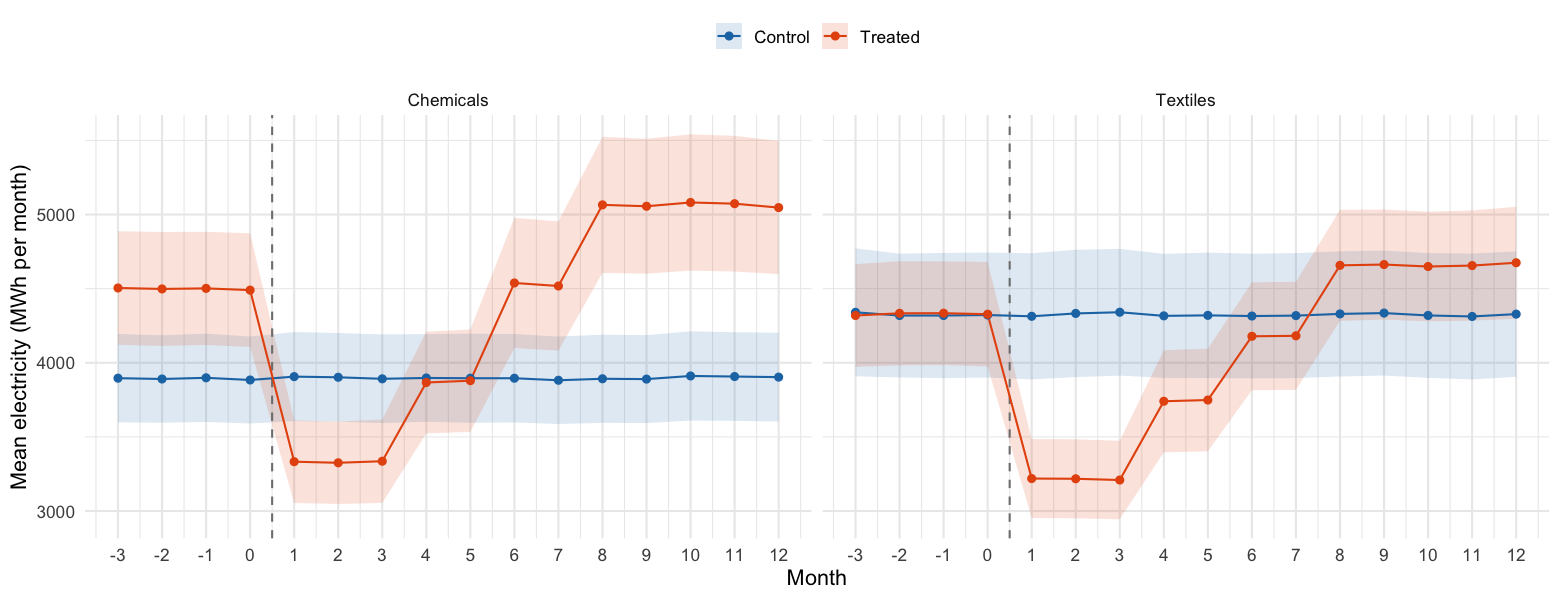

In [ ]:
# 1.6 Mean electricity use by month, treated vs control, in each sector
# (95% confidence intervals). Dashed line: consulting begins in month 1.
options(repr.plot.width = 13, repr.plot.height = 5)
firms |>
  group_by(sector, group, month) |>
  summarise(mean = mean(electricity), se = sd(electricity) / sqrt(n()), .groups = "drop") |>
  ggplot(aes(month, mean, colour = group, fill = group)) +
  geom_ribbon(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se), alpha = 0.15, colour = NA) +
  geom_vline(xintercept = 0.5, linetype = "dashed", colour = "grey50") +
  geom_line() +
  geom_point() +
  facet_wrap(~ sector) +
  scale_colour_manual(values = group_colours) +
  scale_fill_manual(values = group_colours) +
  scale_x_continuous(breaks = -3:12) +
  labs(x = "Month", y = "Mean electricity (MWh per month)", colour = NULL, fill = NULL)

**1.7 Changes relative to each plant's baseline.** In months 1–3 every treated plant uses less electricity than at baseline (between about −16% and −38%), while control plants stay within ±3%: the two distributions do not overlap. In months 9–12 the treated distribution has moved to the right of zero: most treated plants now use more electricity than before, but some still use less.

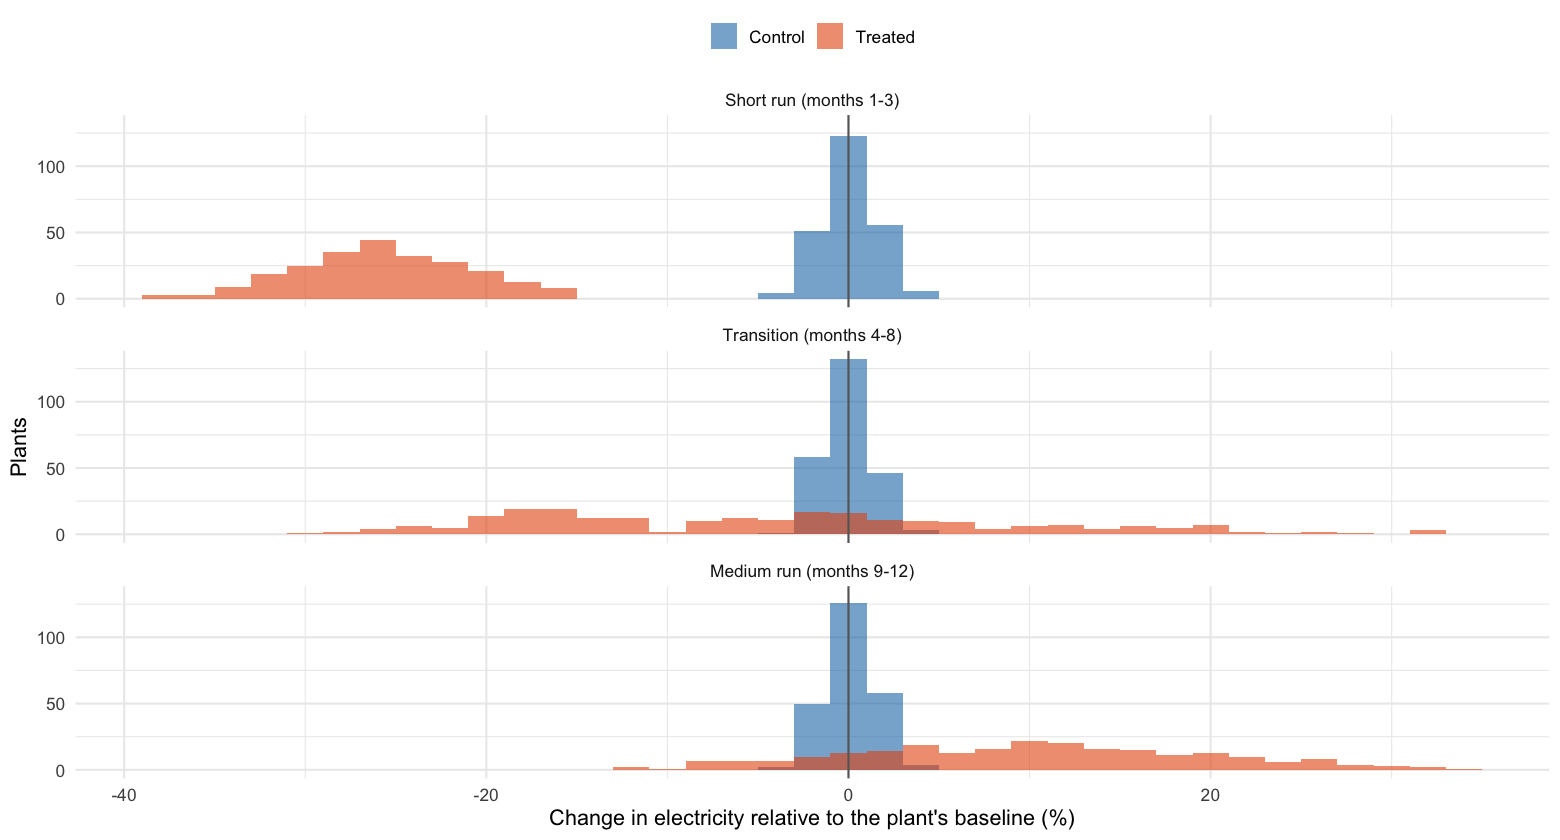

In [ ]:
# 1.7 Distribution of each plant's change in electricity relative to its own baseline
# (mean of months -3 to 0), in each post-programme window
options(repr.plot.width = 13, repr.plot.height = 7)
plants |>
  transmute(
    group,
    `Short run (months 1-3)` = pct_change(E_s, E_b),
    `Transition (months 4-8)` = pct_change(E_t, E_b),
    `Medium run (months 9-12)` = pct_change(E_m, E_b)
  ) |>
  pivot_longer(-group, names_to = "window", values_to = "change") |>
  mutate(window = fct_inorder(window)) |>
  ggplot(aes(change, fill = group)) +
  geom_histogram(binwidth = 2, position = "identity", alpha = 0.6) +
  geom_vline(xintercept = 0, colour = "grey40") +
  facet_wrap(~ window, ncol = 1) +
  scale_fill_manual(values = group_colours) +
  labs(x = "Change in electricity relative to the plant's baseline (%)", y = "Plants", fill = NULL)

**1.8 Individual trajectories.** Each treated plant's path is a step function: a drop in month 1, a flat period, then a single jump to a level above baseline. The month of the jump differs across plants and coincides with the staffing-review month (4, 6 or 8). Control plants only show noise around zero.

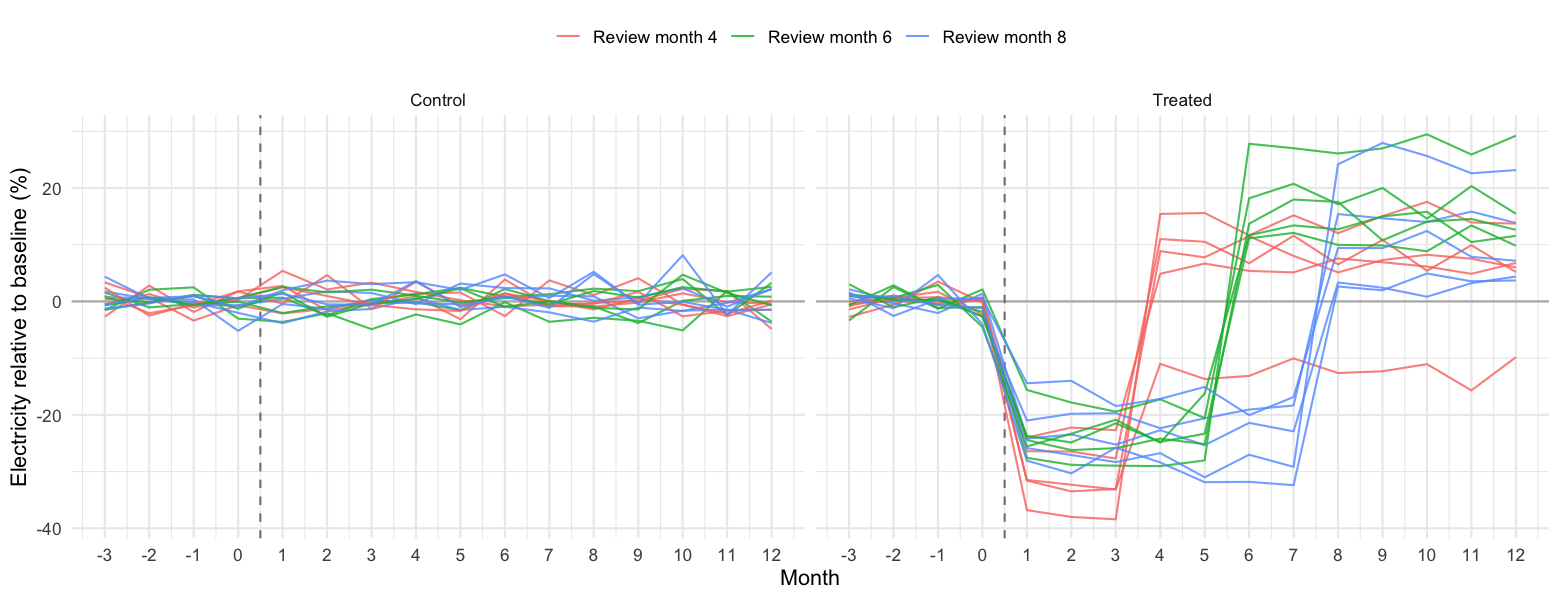

In [ ]:
# 1.8 Individual trajectories: electricity relative to baseline for five random plants
# per group and staffing-review cohort
set.seed(2026)
sample_ids <- plants |> group_by(group, adjust_month) |> slice_sample(n = 5) |> pull(firm_id)

options(repr.plot.width = 13, repr.plot.height = 5)
firms |>
  filter(firm_id %in% sample_ids) |>
  left_join(select(plants, firm_id, E_b), by = "firm_id") |>
  ggplot(aes(month, pct_change(electricity, E_b), group = firm_id,
             colour = paste("Review month", adjust_month))) +
  geom_hline(yintercept = 0, colour = "grey70") +
  geom_vline(xintercept = 0.5, linetype = "dashed", colour = "grey50") +
  geom_line(alpha = 0.8) +
  facet_wrap(~ group) +
  scale_x_continuous(breaks = -3:12) +
  labs(x = "Month", y = "Electricity relative to baseline (%)", colour = NULL)

# Part 2: Find the question, then develop an explanation

## 2. What does the time pattern tell you?

> Look more closely at the evolution of electricity use. Does a single average for the period after consulting give an adequate account? Identify the features of the time path that would matter to a policymaker, and decide how to present them clearly.
>
> Compare your conclusions across treated and control plants and consider whether the average hides differences across firms. State the main empirical pattern that your subsequent analysis needs to explain. Keep a description of that pattern separate from an explanation of why it occurs.

**2.1 The time path by staffing-review cohort.** Splitting plants by their review month shows three phases for treated plants. From month 1 until the month before their review, electricity is about 26% below baseline, and labor and output do not change. In the review month itself, labor jumps by about 48%, output by about 22% and electricity to about 10% *above* baseline. After that all three stay flat until month 12. Control plants stay at baseline throughout, in every cohort.

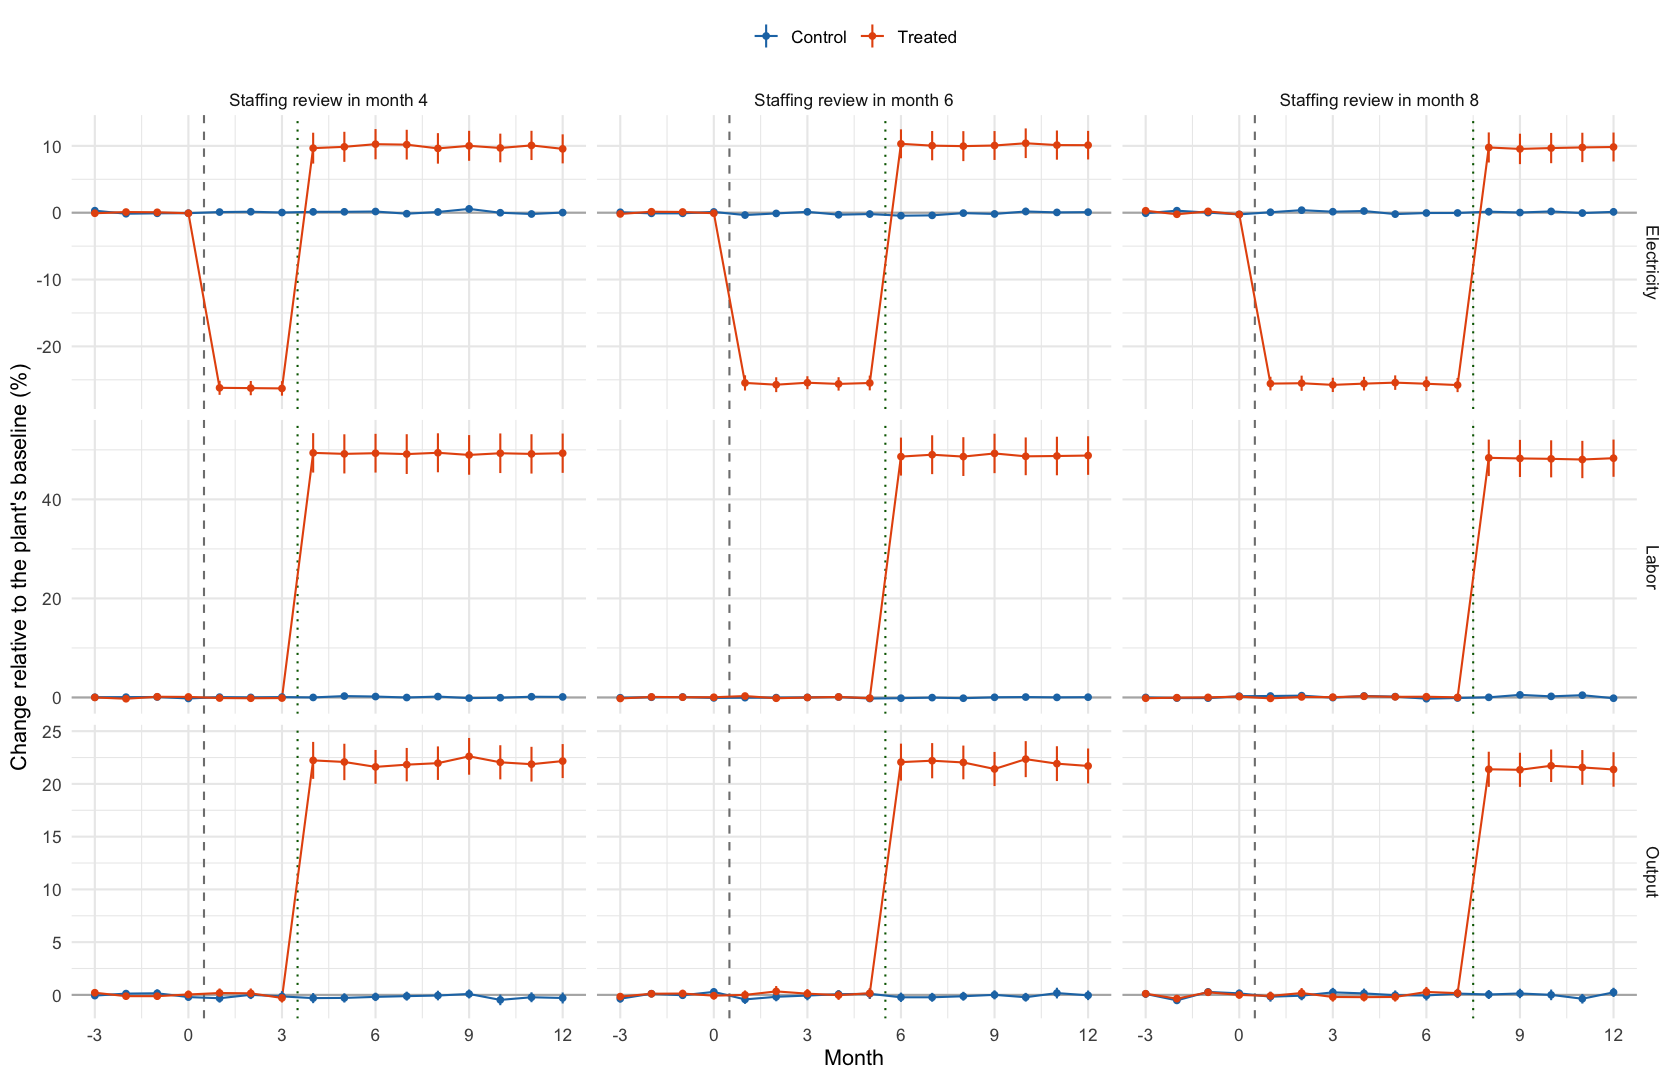

In [ ]:
# 2.1 Time path of electricity, labor and output relative to each plant's baseline,
# by staffing-review cohort (means with 95% confidence intervals).
# Dashed line: consulting begins. Dotted line: the cohort's staffing-review month.
monthly_changes <- firms |>
  left_join(select(plants, firm_id, q_b, L_b, E_b), by = "firm_id") |>
  mutate(Electricity = pct_change(electricity, E_b), Labor = pct_change(labor, L_b),
         Output = pct_change(output, q_b)) |>
  pivot_longer(c(Electricity, Labor, Output), names_to = "variable", values_to = "change") |>
  mutate(variable = factor(variable, levels = c("Electricity", "Labor", "Output")),
         cohort = paste("Staffing review in month", adjust_month))

options(repr.plot.width = 14, repr.plot.height = 9)
monthly_changes |>
  group_by(variable, cohort, adjust_month, group, month) |>
  summarise(mean = mean(change), se = sd(change) / sqrt(n()), .groups = "drop") |>
  ggplot(aes(month, mean, colour = group)) +
  geom_hline(yintercept = 0, colour = "grey70") +
  geom_vline(xintercept = 0.5, linetype = "dashed", colour = "grey50") +
  geom_vline(aes(xintercept = adjust_month - 0.5), linetype = "dotted", colour = "darkgreen") +
  geom_line() +
  geom_pointrange(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se), size = 0.15) +
  facet_grid(variable ~ cohort, scales = "free_y") +
  scale_colour_manual(values = group_colours) +
  scale_x_continuous(breaks = seq(-3, 12, 3)) +
  labs(x = "Month", y = "Change relative to the plant's baseline (%)", colour = NULL)

**2.2 A single post-programme average is misleading.** Averaged over months 1–12, treated plants use 4.9% less electricity than control plants. That figure mixes a 26% saving with a 10% increase, and it depends on calendar timing: +0.8% for plants reviewed in month 4, −4.6% for month 6 and −11.0% for month 8. The response in each phase is the same across cohorts, so these differences reflect only how long labor stayed fixed. The single average also hides that the sign of the effect reverses.

In [ ]:
# 2.2 Does a single post-programme average describe the path? Treated minus control
# difference in the mean % change in electricity relative to baseline, for the whole
# post-programme period (months 1-12) and for each window, by cohort.
electricity_changes <- monthly_changes |> filter(variable == "Electricity", month >= 1)
periods <- bind_rows(
  electricity_changes |> mutate(period = "Months 1-12 (single average)"),
  electricity_changes |> mutate(period = as.character(window))
)

bind_rows(periods, periods |> mutate(cohort = "All plants")) |>
  group_by(period, cohort, group) |>
  summarise(change = mean(change), .groups = "drop") |>
  pivot_wider(names_from = group, values_from = change) |>
  mutate(period = factor(period, levels = c("Months 1-12 (single average)", window_levels[-1])),
         difference = round(Treated - Control, 1)) |>
  select(period, cohort, difference) |>
  pivot_wider(names_from = cohort, values_from = difference) |>
  arrange(period)

period,All plants,Staffing review in month 4,Staffing review in month 6,Staffing review in month 8
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Months 1-12 (single average),-4.9,0.8,-4.6,-11.0
Short run,-25.9,-26.3,-25.4,-25.8
Transition,-4.2,9.8,-3.9,-18.5
Medium run,9.8,9.7,10.1,9.6


**2.3 The average hides differences across plants.** In the medium run, 89% of treated Chemicals plants and 78% of treated Textiles plants use more electricity than at baseline (+12.0% and +7.8% on average). Within each sector the spread is wide: in Textiles from −5% at the 10th percentile to +22% at the 90th. About one treated plant in six still saves electricity, while others use over 20% more. Control plants are centred on zero in both sectors.

**Features a policymaker needs.**

1. The size of the initial saving (about a quarter of electricity).
2. How long it lasts: exactly as long as labor is fixed, here 3 to 7 months.
3. The reversal, and its sign: in the medium run electricity is above its pre-programme level.
4. The medium-run level is stable through month 12, so it is not a temporary spike.
5. How much the medium-run response varies across plants.

### Main empirical pattern (description only)

Consulting immediately lowers treated plants' electricity use by about a quarter, uniformly across plants, while their labor and output are unchanged. In the month each plant's staffing review allows labor to change, its labor and output rise sharply and its electricity jumps above its pre-programme level, where it stays. The medium-run increase averages about 10% but ranges from savings to increases above 20%, and is larger in Chemicals. Control plants do not change.

*Why* this happens is the subject of Question 4.

sector,group,plants,mean,p10,median,p90,share_above_baseline
<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Chemicals,Control,120,0.16,-1.33,0.07,2.16,0.52
Chemicals,Treated,120,11.98,-0.10,12.36,23.96,0.89
Textiles,Control,120,-0.02,-1.81,0.00,1.72,0.50
Textiles,Treated,120,7.82,-5.12,7.25,22.20,0.78


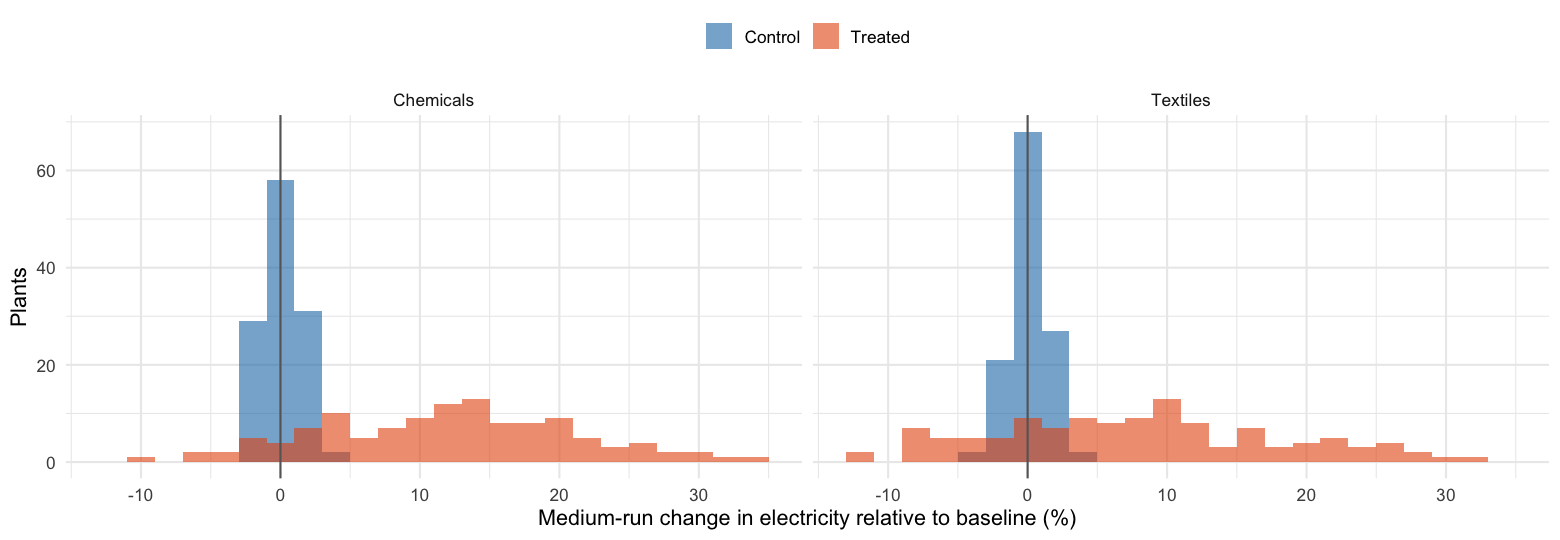

In [ ]:
# 2.3 Does the average hide differences across plants? Medium-run change in electricity
# relative to baseline (months 9-12 vs months -3 to 0), by sector
plants |>
  mutate(change_m = pct_change(E_m, E_b)) |>
  group_by(sector, group) |>
  summarise(plants = n(), mean = mean(change_m), p10 = quantile(change_m, 0.1),
            median = median(change_m), p90 = quantile(change_m, 0.9),
            share_above_baseline = mean(change_m > 0), .groups = "drop") |>
  mutate(across(where(is.double), \(x) round(x, 2)))

options(repr.plot.width = 13, repr.plot.height = 4.5)
plants |>
  ggplot(aes(pct_change(E_m, E_b), fill = group)) +
  geom_histogram(binwidth = 2, position = "identity", alpha = 0.6) +
  geom_vline(xintercept = 0, colour = "grey40") +
  facet_wrap(~ sector) +
  scale_fill_manual(values = group_colours) +
  labs(x = "Medium-run change in electricity relative to baseline (%)", y = "Plants", fill = NULL)

## 3. Evaluate the programme

> Use the random assignment to assess whether consulting achieved its stated objective. Explain your comparison, your choice of outcome and time windows, and why the comparison is informative about the programme rather than simply about differences across plants or changes over time.
>
> Report the size and uncertainty of the effects you consider relevant. Treat plants, rather than their repeated monthly observations, as the independent assignment units. Does the policy assessment depend on the horizon? Be precise about the difference between an average plant's proportional response and the change in total electricity consumption.

### Comparison

For each plant we compute the change in its mean electricity from the baseline (months −3 to 0) to a post-programme window. We then compare the mean change of treated plants with that of control plants in the same randomisation stratum (sector × review month), and average across strata. This is a difference-in-differences at the plant level:

(treated − control, window) − (treated − control, baseline)

### Outcome

Electricity use, because reducing it is the programme's stated objective. We report it in three ways:
- as the plant's **% change** relative to its own baseline, which makes plants of very different sizes comparable;
- as the **% change in total electricity** of the group;
- in **MWh** per plant per month.

### Time windows

- **Short run, months 1–3:** every plant's labor is fixed.
- **Medium run, months 9–12:** every plant has passed its staffing review.
- **Transition, months 4–8:** a mix of the two whose average depends on the cohort mix, as Question 2 showed.

We also show the effect month by month.

### Why the comparison is about the programme

- **Not differences across plants.** Consulting was assigned at random within strata. Prices are balanced, and the small chance difference in size is removed by comparing each plant with its own baseline.
- **Not changes over time.** Treated and control plants are observed in the same months and face the same staffing arrangements. Anything common to all plants cancels out, and control plants do not change at all.
- **Pre-trends.** In the baseline months the monthly effects are zero (Figure 3.2).
- **Brief assumptions.** No spillovers between plants, and consulting is the only difference between the groups.

### Uncertainty

Each plant contributes one observation per window, so plants are the independent units. Standard errors are HC2-robust. The interval for the total is a bootstrap with 2,000 replications that resamples plants within stratum and group. N = 480 plants (240 treated, 240 control).

In [ ]:
# 3.1 Effect of consulting on electricity, by time window. One observation per plant:
# its mean electricity in the window compared with its own baseline (months -3 to 0).
# - Average plant's proportional response: treated minus control mean % change,
#   within strata, HC2 standard errors.
# - Total electricity: % change in the summed electricity of treated plants minus that
#   of control plants (bootstrap interval over plants).
# - Level: MWh per plant per month, and scaled to the 240 treated plants.
set.seed(2026)
windows <- c("Short run (months 1-3)" = "E_s", "Transition (months 4-8)" = "E_t",
             "Medium run (months 9-12)" = "E_m")

electricity_effects <- imap_dfr(windows, function(column, label) {
  d <- plants |> mutate(pct = pct_change(.data[[column]], E_b), level = .data[[column]] - E_b)
  proportional <- plant_effect(d, "pct")
  total <- total_effect(d, "E_b", column)
  level <- plant_effect(d, "level")
  tibble(
    window = label,
    `Average plant (%)` = proportional$estimate,
    `95% CI, average plant` = sprintf("[%.1f, %.1f]", proportional$conf.low, proportional$conf.high),
    `Total electricity (%)` = total$estimate,
    `95% CI, total` = sprintf("[%.1f, %.1f]", total$conf.low, total$conf.high),
    `MWh per plant-month` = level$estimate,
    `95% CI, MWh` = sprintf("[%.0f, %.0f]", level$conf.low, level$conf.high),
    `MWh per month, 240 treated plants` = 240 * level$estimate
  )
})
electricity_effects |> mutate(across(where(is.double), \(x) round(x, 1)))

window,Average plant (%),"95% CI, average plant",Total electricity (%),"95% CI, total",MWh per plant-month,"95% CI, MWh","MWh per month, 240 treated plants"
<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<dbl>
Short run (months 1-3),-25.9,"[-26.5, -25.2]",-26.0,"[-26.7, -25.3]",-1146.3,"[-1223, -1070]",-275118.2
Transition (months 4-8),-4.2,"[-5.6, -2.8]",-3.9,"[-5.0, -2.8]",-173.8,"[-243, -105]",-41707.5
Medium run (months 9-12),9.8,"[8.6, 11.1]",10.1,"[8.6, 11.4]",444.2,"[375, 514]",106596.2


### Result

**Short run (months 1–3).** Consulting lowered electricity by 25.9% for the average plant (95% CI −26.5% to −25.2%). Total electricity of treated plants fell by 26.0% (−26.7% to −25.3%). That is about 1,150 MWh per plant per month, or about 275,000 MWh per month across the 240 treated plants.

**Medium run (months 9–12).** Consulting *raised* electricity by 9.8% for the average plant (8.6% to 11.1%) and total electricity by 10.1% (8.6% to 11.4%): about +440 MWh per plant per month, or +107,000 MWh per month in total.

**The assessment depends on the horizon.** An evaluation after three months would conclude that the programme cut electricity by a quarter. An evaluation after a year concludes that it increased electricity by a tenth. On the stated objective the programme fails in the medium run. Both estimates are very precise, so the reversal is not noise.

**Average plant vs total.**
- **Average plant's proportional response:** the mean of each plant's % change. It weights every plant equally.
- **Change in total electricity:** sums MWh first, so it weights plants by their baseline electricity.

The two are close here (−25.9% vs −26.0% in the short run, +9.8% vs +10.1% in the medium run). In the medium run the total rises slightly more, because plants that use more electricity respond a little more. The total is what matters for the environment. The plant average describes the typical plant's behaviour.

A third measure is also not the same: the mean log change, 9.0 log points in the medium run. It is smaller than the mean % change because of the spread across plants.

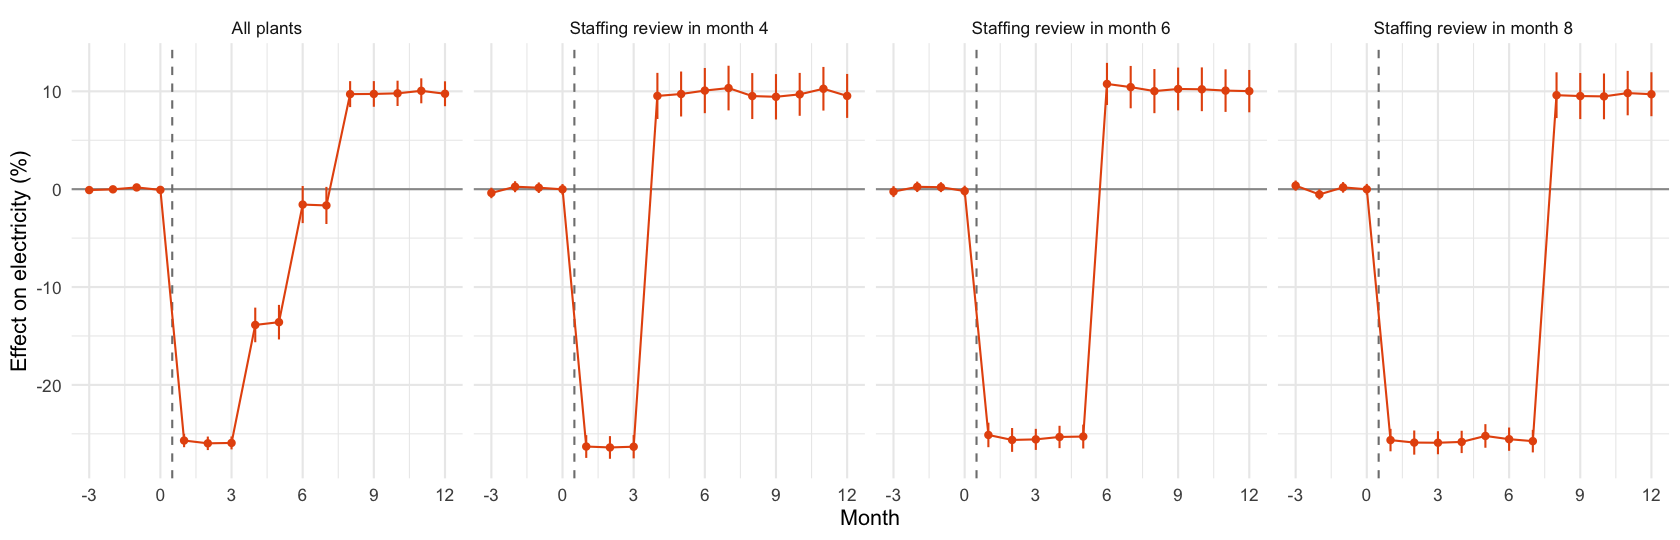

In [ ]:
# 3.2 Effect on electricity month by month (% change relative to baseline, treated minus
# control within strata, 95% CI), for all plants and by cohort. The baseline months show
# that the groups did not differ before consulting.
electricity_monthly <- monthly_changes |> filter(variable == "Electricity")
monthly_effects <- bind_rows(electricity_monthly |> mutate(cohort = "All plants"), electricity_monthly) |>
  group_by(cohort, month) |>
  group_modify(\(d, key) plant_effect(d, "change")) |>
  ungroup()

options(repr.plot.width = 14, repr.plot.height = 4.5)
monthly_effects |>
  ggplot(aes(month, estimate)) +
  geom_hline(yintercept = 0, colour = "grey60") +
  geom_vline(xintercept = 0.5, linetype = "dashed", colour = "grey50") +
  geom_pointrange(aes(ymin = conf.low, ymax = conf.high), colour = "#E6550D", size = 0.2) +
  geom_line(colour = "#E6550D") +
  facet_wrap(~ fct_relevel(cohort, "All plants"), nrow = 1) +
  scale_x_continuous(breaks = seq(-3, 12, 3)) +
  labs(x = "Month", y = "Effect on electricity (%)")

**3.2 Month by month.**
- **Baseline months:** the effect is zero.
- **From month 1:** it is about −26% in every cohort.
- **From the review month:** it switches to about +10%, in month 4, 6 or 8 depending on the cohort.

The transition-window estimate (−4.2%) is therefore just a mix of the two phases.

**3.3 Output and labor.** In the short run consulting changes neither output (+0.2%, 95% CI −0.1 to 0.4) nor labor (−0.1%, −0.3 to 0.1). In the medium run, output rises by 21.9% (21.0 to 22.9) and labor by 48.7% (46.4 to 50.9). The programme changed much more than electricity use.

**3.4 By sector.** The short-run saving is the same in both sectors (−25.8% in Chemicals, −25.9% in Textiles). The medium-run increase is larger in Chemicals, +11.8% (10.2 to 13.5), than in Textiles, +7.8% (6.0 to 9.7).

In [ ]:
# 3.3 Effects on output and labor (average plant, % change relative to baseline)
tribble(
  ~variable, ~window, ~new, ~old,
  "Output", "Short run (months 1-3)", "q_s", "q_b",
  "Output", "Medium run (months 9-12)", "q_m", "q_b",
  "Labor", "Short run (months 1-3)", "L_s", "L_b",
  "Labor", "Medium run (months 9-12)", "L_m", "L_b"
) |>
  pmap_dfr(function(variable, window, new, old) {
    d <- plants |> mutate(pct = pct_change(.data[[new]], .data[[old]]))
    tibble(variable, window, plant_effect(d, "pct"))
  }) |>
  mutate(across(where(is.double), \(x) round(x, 2)))

variable,window,estimate,std.error,conf.low,conf.high,p.value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Output,Short run (months 1-3),0.17,0.13,-0.09,0.42,0.20
Output,Medium run (months 9-12),21.92,0.47,21.00,22.85,0.00
Labor,Short run (months 1-3),-0.11,0.10,-0.32,0.09,0.28
Labor,Medium run (months 9-12),48.65,1.13,46.44,50.87,0.00


In [ ]:
# 3.4 Effect on electricity by sector (average plant, % change relative to baseline)
expand_grid(sector_name = c("Chemicals", "Textiles"),
            window = c("Short run (months 1-3)", "Medium run (months 9-12)")) |>
  pmap_dfr(function(sector_name, window) {
    column <- if (str_detect(window, "Short")) "E_s" else "E_m"
    d <- plants |> filter(sector == sector_name) |> mutate(pct = pct_change(.data[[column]], E_b))
    tibble(sector = sector_name, window, plant_effect(d, "pct"))
  }) |>
  mutate(across(where(is.double), \(x) round(x, 2)))

sector,window,estimate,std.error,conf.low,conf.high,p.value
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Chemicals,Short run (months 1-3),-25.80,0.44,-26.66,-24.94,0
Chemicals,Medium run (months 9-12),11.82,0.83,10.18,13.46,0
Textiles,Short run (months 1-3),-25.92,0.48,-26.86,-24.99,0
Textiles,Medium run (months 9-12),7.84,0.94,5.99,9.69,0


## 4. Use Unit 3 to make sense of the findings

> Imagine that plant $i$ has the technology $q = A_i\sqrt{\min\{L, \eta E\}}$. $A_i > 0$ is persistent plant productivity; $\eta > 0$ measures the energy services obtained from physical electricity, in units comparable with labor. Consulting aims to improve $\eta$. Plants take their observed prices as given and seek to maximise operating profits, $pq - wL - cE$.
>
> **Institutional context.** From month 1, pre-existing staffing commitments fix paid labor until the recorded adjustment month (4, 6 or 8). From that month onward labor can adjust freely; electricity can always adjust.
>
> Use the theory learned in Unit 3 to construct an explanation for the findings so far and how they vary across horizons. State the assumptions your argument requires and support it with the calculations and economic diagrams you judge necessary. Decide which choices and constraints matter at each horizon. Explain what your account would lead you to look for elsewhere in the data. Distinguish properties assumed by the technology from conclusions supported by observed behaviour.

### The technology: effective input

Labor and energy services are perfect complements. Any labor beyond $\eta E$, or electricity beyond $L/\eta$, adds nothing to output, so a profit-maximising plant wastes neither and uses

$$L = \eta E \equiv x.$$

We call $x$ the plant's **effective input**. Producing with $x$ costs labor $x$ and electricity $x/\eta$, so the unit cost of effective input is

$$w + \frac{c}{\eta}.$$

A higher $\eta$ lowers this cost: consulting makes energy services cheaper.

### Baseline: all inputs free

The plant chooses $x$ to maximise $pA\sqrt{x} - (w + c/\eta)\,x$. The first-order condition sets the marginal revenue product of $x$ equal to its unit cost:

$$\frac{pA}{2\sqrt{x}} = w + \frac{c}{\eta_0} \;\Rightarrow\; x_0 = \left(\frac{pA}{2(w + c/\eta_0)}\right)^2, \qquad L_0 = x_0,\quad E_0 = \frac{x_0}{\eta_0},\quad q_0 = A\sqrt{x_0}.$$

Output rises with the square root of $x$, so at the optimum revenue is exactly **twice** variable cost: $pq = 2(wL + cE)$.

### Short run: labor fixed at $\bar L = x_0$, efficiency rises to $\eta_1 > \eta_0$

Labor is already paid, so the only choice is electricity.
- **Buying more electricity than $\bar L/\eta_1$ is wasted:** there is no labor to combine it with.
- **Buying less loses output.** The value of one more unit of $x$ at $\bar L$ is $pA/(2\sqrt{\bar L}) = w + c/\eta_0$. With labor sunk, the plant only pays $c/\eta_1$ for that unit, which is smaller.

So the plant keeps output where it was and buys exactly

$$E_S = \frac{\bar L}{\eta_1} \;\Rightarrow\; \frac{E_S}{E_0} = \frac{\eta_0}{\eta_1}, \qquad q_S = q_0,\quad L_S = L_0.$$

Electricity falls by exactly the efficiency gain, output and labor do not move, and profits rise by $c(E_0 - E_S)$. The plant would like to expand, because effective input is now cheaper than it is worth, but the labor constraint stops it.

### Medium run: labor free again

The unit cost of effective input has fallen from $w + c/\eta_0$ to $w + c/\eta_1$, so the plant expands to

$$\frac{x_1}{x_0} = \left(\frac{w + c/\eta_0}{w + c/\eta_1}\right)^2.$$

Labor rises by this factor, output by its square root, and electricity by

$$\frac{E_1}{E_0} = \frac{x_1/\eta_1}{x_0/\eta_0} = \frac{\eta_0/\eta_1}{\left(1 - s + s\,\eta_0/\eta_1\right)^2}, \qquad s = \frac{c/\eta_0}{w + c/\eta_0} = \frac{cE_0}{wL_0 + cE_0}.$$

Two forces act on electricity:
- **Efficiency effect:** less electricity per unit of $x$.
- **Scale effect:** more $x$, because energy services are cheaper.

For a small change, the elasticity of electricity with respect to efficiency is

$$\frac{d\ln E}{d\ln\eta} = 2s - 1.$$

With $q \propto \sqrt{x}$, the demand for effective input has a price elasticity of 2. A 1% fall in the cost of energy services lowers the unit cost of $x$ by $s$%, which raises $x$ by $2s$%.

Electricity therefore rises (backfire) when electricity's cost share exceeds one half. For a finite gain $g = \ln(\eta_1/\eta_0)$, the condition is $s > 1/(1 + e^{-g/2})$.

### Calculations for our plants

The average treated plant has $s \approx 0.68$, well above one half, and efficiency rises by about 35% (Question 5). The model then predicts:

| Horizon | Electricity | Labor | Output |
|---|---|---|---|
| Short run | −26% | 0% | 0% |
| Medium run | +9% | +48% | +21% |

This is almost exactly the observed pattern (table below the diagrams).

### Choices and constraints at each horizon

| Horizon | Choices | Binding constraint | What drives electricity |
|---|---|---|---|
| Baseline | $L$, $E$ | none | $x_0$ at unit cost $w + c/\eta_0$ |
| Short run (month 1 to review month − 1) | $E$ only | $L = \bar L$ | efficiency effect only: $E = \bar L/\eta_1$ |
| Medium run (from review month) | $L$, $E$ | none | efficiency and scale effects |

The jump coincides with the review month because that is when the labor constraint stops binding. It is not tied to a fixed time since consulting began.

### Assumptions

- Plants maximise operating profit, take prices as given and face constant prices: no fall in the output price when they expand.
- Production uses fixed proportions with no waste, and $A_i$ is unchanged by consulting.
- Consulting changes only $\eta$, the change is permanent, and it happens in month 1.
- Labor is exactly fixed until the review month and free afterwards, with no adjustment costs. Electricity is always free.
- There are no other variable inputs, no inventories, and no entry or exit (as in the brief).

### Diagrams

**Panel A, input space.** The isoquants are L-shaped, with corners on the ray $L = \eta E$. Higher efficiency rotates the ray, moving the corner for the same output to the left.
- **Short run (B → S):** with labor fixed, the plant moves left along the dotted line to the new corner. Same output, less electricity.
- **Medium run (S → M):** once labor is free, it expands along the new ray to a higher isoquant, past the baseline level of electricity.

**Panel B, effective input.** Consulting lowers the unit cost of effective input. In the short run the plant cannot go beyond $x_0$, although the marginal cost of $x$ with labor already paid, $c/\eta_1$, is far below its value. In the medium run it expands to $x_1$, where the marginal revenue product equals the new unit cost.

In [ ]:
# 4.1 A check implied by profit maximisation with q = A sqrt(x): revenue equals twice
# variable cost, p q = 2 (w L + c E). Ratio of revenue to variable cost by plant.
firms |>
  filter(window %in% c("Baseline", "Short run", "Medium run")) |>
  mutate(ratio = output_price * output / (wage * labor + energy_price * electricity)) |>
  group_by(group, window) |>
  summarise(mean = mean(ratio), p10 = quantile(ratio, 0.1), p90 = quantile(ratio, 0.9),
            .groups = "drop") |>
  mutate(across(where(is.double), \(x) round(x, 3)))

group,window,mean,p10,p90
<fct>,<fct>,<dbl>,<dbl>,<dbl>
Control,Baseline,2.002,1.942,2.060
Control,Short run,1.998,1.942,2.055
Control,Medium run,1.999,1.934,2.063
Treated,Baseline,2.002,1.942,2.059
Treated,Short run,2.438,2.242,2.644
Treated,Medium run,2.002,1.947,2.059


**4.1 Revenue and cost.** At baseline the ratio of revenue to variable cost is 2.00 for both groups, with little spread (1.94–2.06), as profit maximisation with this technology implies.

In the short run, treated plants reach 2.44: electricity costs fell while revenue did not, because the labor constraint keeps them away from their new optimum. In the medium run the ratio returns to 2.00, so the plants have reoptimised. Control plants stay at 2.00 throughout.

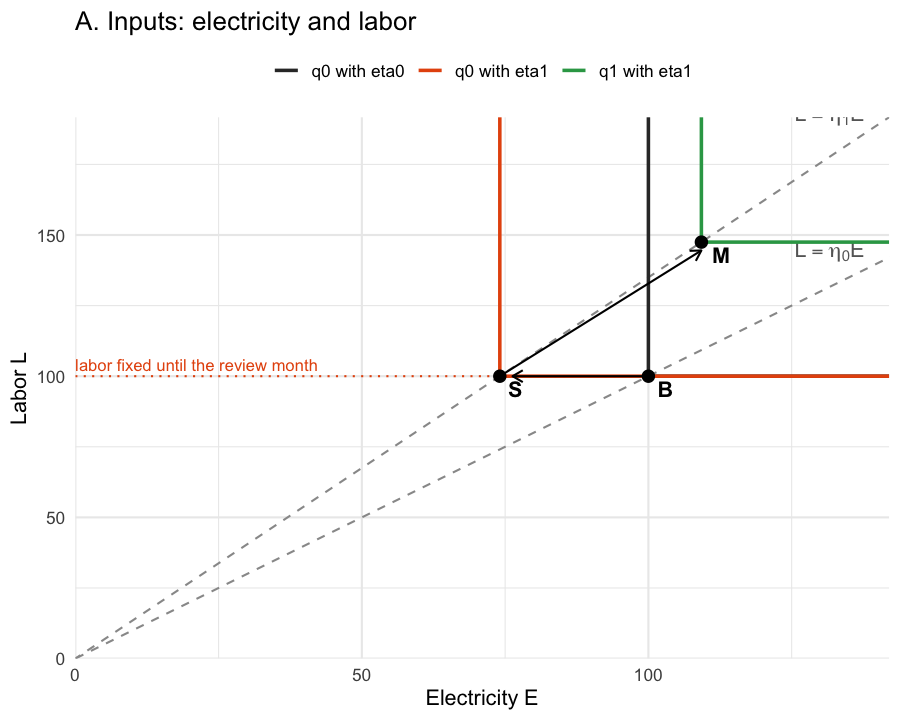

E,L,label,q
<dbl>,<dbl>,<chr>,<dbl>
0.0,0.0,B,0.0
-25.9,0.0,S,0.0
9.2,47.5,M,21.4


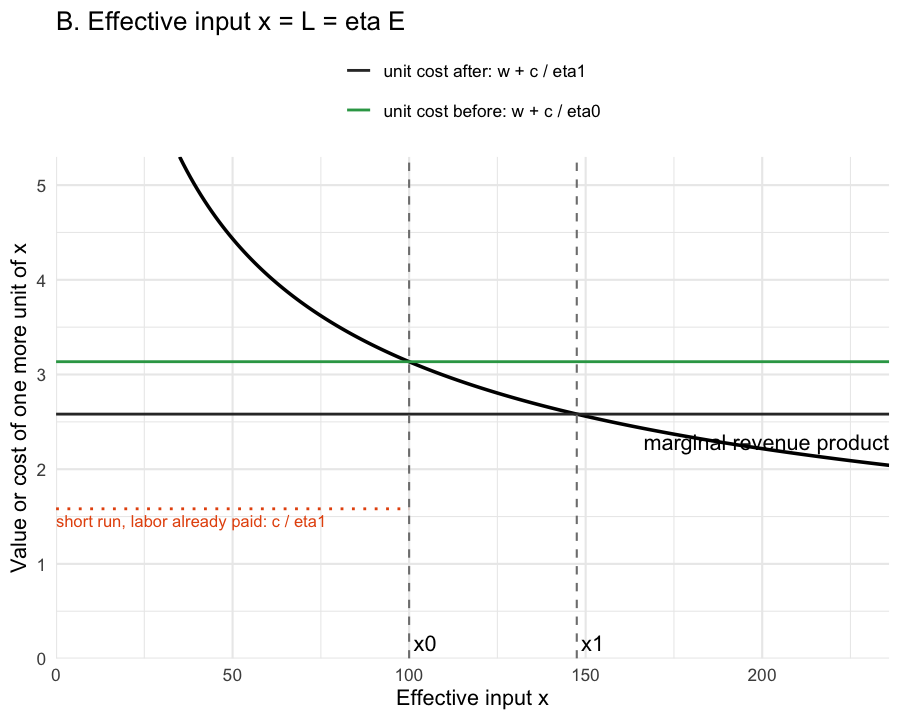

In [ ]:
# 4.2 Economic diagrams for an illustrative plant. Units are normalised (wage w = 1,
# eta0 = 1, baseline effective input x0 = 100). Electricity's share of input cost is set
# to the treated plants' average (about 0.68) and efficiency rises by 35%, close to the
# gain estimated in Question 5.
s_illustrative <- mean(plants$energy_share[plants$treated == 1])
w <- 1
c_illustrative <- w * s_illustrative / (1 - s_illustrative)   # so that (c/eta0) / (w + c/eta0) = s
pA <- 2 * (w + c_illustrative) * sqrt(100)                    # so that x0 = 100
diagrams <- efficiency_diagrams(pA, w, c_illustrative, eta0 = 1, eta1 = 1.35)

options(repr.plot.width = 7.5, repr.plot.height = 6)
diagrams$panel_a
diagrams$panel_b

# Electricity, labor and output at B, S and M, relative to the baseline
diagrams$points |>
  mutate(q = sqrt(L), across(c(E, L, q), \(v) round(pct_change(v, first(v)), 1)))

### What the account leads us to look for elsewhere in the data

1. **Short run:** labor and output unchanged, and electricity down by exactly the efficiency gain (Question 5).
2. **Persistence:** the ratio $L/E$ rises by $\eta_1/\eta_0$ from month 1 and stays there after labor adjusts (Question 5).
3. **Medium-run levels** predicted from baseline parameters: labor growing by twice the log growth of output, and revenue back to twice cost (Questions 4.1 and 6(a)).
4. **Output growth** large enough to explain the electricity increase: $\Delta\ln q > g/2$ (Question 6(b)).
5. **Heterogeneity:** larger medium-run electricity increases where electricity is a larger share of cost, $s$ (Question 6(c)).
6. **Input relationships and timing:** labor and electricity changes one for one after month 1, and responses exactly at the review month (Question 6(d)).

### Assumed vs supported by behaviour

**Assumed by the technology:**
- fixed proportions;
- an output elasticity of one half, so revenue equals twice cost at an optimum;
- $\eta$ entering only through electricity.

**Supported by behaviour:**
- plants are at a profit maximum at baseline and again in the medium run (4.1);
- they keep output unchanged in the short run rather than cutting it;
- they expand only once labor is free.

The fact that $L/E$ measures $\eta$ comes from the technology; the data cannot test it separately from no waste.

# Part 3: Turn your explanation into further evidence

## 5. Can the initial response reveal the efficiency gain?

> Using your explanation from Question 4, can you use the observations before the intervention and in **months 1–3** to estimate the technological effect of consulting? Explain which observed quantities you need and why. Establish the conditions under which the initial electricity response is informative about efficiency, and check whether the accompanying observations support those conditions. Distinguish the level of $\eta$ from its percentage change, and use the control plants to assess the change attributable to consulting. Allow for recording noise by combining observations where appropriate.
>
> Then investigate whether the efficiency change you infer appears to persist later. Explain how you would assess this once other input quantities can change. Be clear about which parts of the conclusion depend on the proposed technology.

### Quantities we need and why

Without waste, $L = \eta E$, so the **level** of efficiency is labor per MWh:

$$\eta = \frac{L}{E}.$$

We need labor and electricity in both periods. With them we have $\eta_0 = L_b/E_b$ at baseline and $\eta_1 = L_s/E_s$ in months 1–3. The **percentage change** is $\eta_1/\eta_0 - 1$, and its log is

$$g = \ln\frac{\eta_1}{\eta_0} = \Delta\ln L - \Delta\ln E.$$

We also need output, to check that the plant is still producing efficiently.

### When the electricity response alone reveals efficiency

The drop in electricity measures the efficiency gain, $\Delta\ln E = -g$, only if:

1. labor did not change ($\Delta\ln L = 0$), which the staffing commitments guarantee;
2. output did not change, so the plant still uses all its labor: effective input $x = L$ is the same, and no labor is idle;
3. prices are constant (true by design) and nothing else changed for treated plants (randomisation).

**The accompanying observations support these conditions** (table 5.1). Between the baseline and months 1–3, treated plants' labor changes by −0.04 log points and their output by +0.03, against −30.05 for electricity. No treated plant moved labor or output by more than 5%.

### Recording noise

We combine the four baseline months and the three short-run months by averaging each plant's quantities within each window before taking ratios.

In [ ]:
# 5.1 Conditions for the short-run response to reveal efficiency: labor and output must
# not change between the baseline and months 1-3. Mean log change x 100 (log points).
plants |>
  group_by(group) |>
  summarise(
    plants = n(),
    output = 100 * mean(log(q_s / q_b)),
    labor = 100 * mean(log(L_s / L_b)),
    electricity = 100 * mean(log(E_s / E_b)),
    labor_per_MWh = 100 * mean(log((L_s / E_s) / (L_b / E_b)))
  ) |>
  mutate(across(where(is.double), \(x) round(x, 2)))

# Treated plants whose short-run labor or output moved by more than 5%
plants |>
  filter(treated == 1) |>
  summarise(labor_moved = sum(abs(log(L_s / L_b)) > 0.05), output_moved = sum(abs(log(q_s / q_b)) > 0.05))

group,plants,output,labor,electricity,labor_per_MWh
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Control,240,-0.14,0.07,0.05,0.02
Treated,240,0.03,-0.04,-30.05,30.01


labor_moved,output_moved
<int>,<int>
0,0


### Estimate

**Level of efficiency.** At baseline, $\eta_0 \approx 0.042$ labor blocks per MWh in both groups: each MWh provides energy services for about 4.2 worker-hours. In months 1–3 it is 0.057 for treated plants and unchanged for controls.

**Change attributable to consulting.** Treated minus control within strata, the change is $g$ = 0.300 log points (95% CI 0.291 to 0.309). Consulting raised efficiency by **35.0%** (33.8% to 36.1%). The control plants' mean change is 0.0002, so there is no change to subtract.

**Noise vs real heterogeneity (5.3).** Among control plants, whose true $g$ is zero, the estimates have a standard deviation of 0.019: this is the noise left after averaging. Among treated plants the standard deviation is 0.066. The gain itself therefore differs across plants, from about +16% to +62%.

In [ ]:
# 5.2 Efficiency level and its change. Without waste L = eta E, so eta = L / E.
# eta0 from the baseline, eta1 from months 1-3 (window means, to average out noise).
# g = log(eta1 / eta0) is the log change in efficiency; the control plants show the
# change that would have happened without consulting.
plants <- plants |>
  mutate(
    eta0 = L_b / E_b,                  # labor blocks of energy services per MWh
    eta1 = L_s / E_s,
    g = log(eta1 / eta0),
    A = (q_b / sqrt(L_b) + q_s / sqrt(L_s)) / 2   # persistent productivity, used in Question 6
  )

plants |>
  group_by(group) |>
  summarise(eta0 = mean(eta0), eta1 = mean(eta1), mean_g = mean(g), sd_g = sd(g),
            min_g = min(g), max_g = max(g)) |>
  mutate(across(where(is.double), \(x) round(x, 4)))

efficiency_effect <- plant_effect(plants, "g")
efficiency_effect |>
  mutate(percent_change_in_eta = 100 * (exp(estimate) - 1),
         percent_low = 100 * (exp(conf.low) - 1), percent_high = 100 * (exp(conf.high) - 1)) |>
  mutate(across(where(is.double), \(x) round(x, 4)))

group,eta0,eta1,mean_g,sd_g,min_g,max_g
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Control,0.0412,0.0412,0.0002,0.0189,-0.0536,0.0494
Treated,0.0419,0.0567,0.3001,0.0657,0.1445,0.4844


estimate,std.error,conf.low,conf.high,p.value,percent_change_in_eta,percent_low,percent_high
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.2999,0.0044,0.2911,0.3086,0,34.9659,33.7962,36.1459


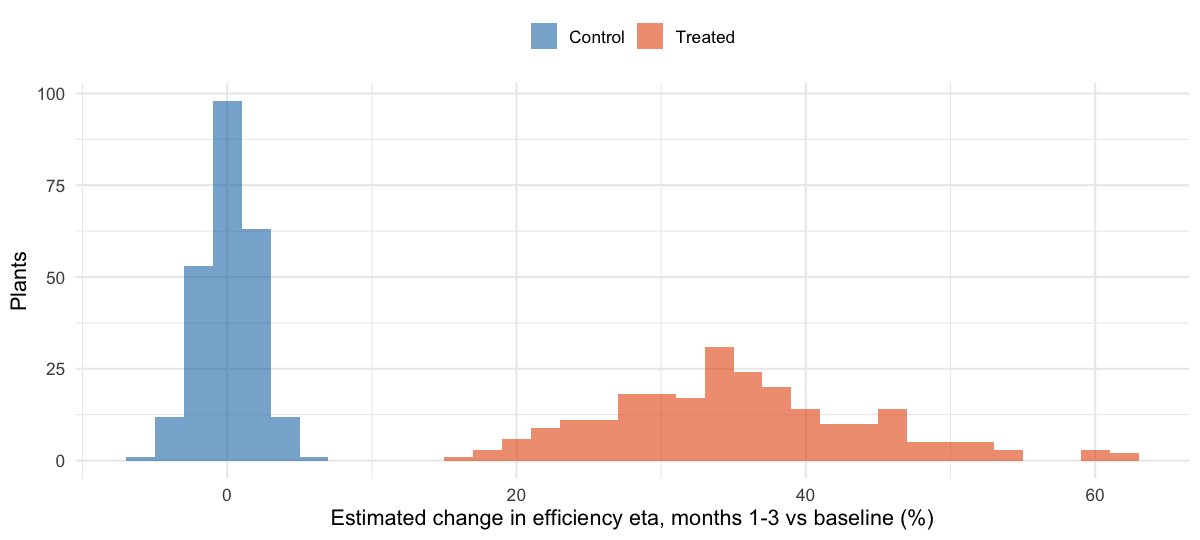

In [ ]:
# 5.3 Distribution of the estimated efficiency change across plants.
# Among control plants the spread is recording noise alone; a wider spread among treated
# plants means the gain itself differs across plants.
options(repr.plot.width = 10, repr.plot.height = 4.5)
plants |>
  ggplot(aes(100 * (exp(g) - 1), fill = group)) +
  geom_histogram(binwidth = 2, position = "identity", alpha = 0.6) +
  scale_fill_manual(values = group_colours) +
  labs(x = "Estimated change in efficiency eta, months 1-3 vs baseline (%)", y = "Plants", fill = NULL)

### Does the efficiency change persist?

**Why electricity alone no longer works.** Once labor can change, the electricity response no longer measures efficiency: electricity rises because the plant expands, and that rise is not a loss of efficiency.

**What we use instead.** We compare labor per MWh in months 9–12 with the baseline. If plants still produce without waste, $L_m/E_m = \eta$, and the scale of production cancels out.

**Result (5.4).**
- **By month:** labor per MWh jumps by about 30 log points in month 1 and stays there in every cohort, including after the review month when both inputs rise.
- **Plant by plant:** the medium-run estimate equals the short-run one on average (difference −0.0001). The plant-level differences have a standard deviation of 0.018, the size of the noise, and the correlation between the two windows is 0.96.
- **Conclusion:** the efficiency gain persists through month 12, and the plants with larger short-run gains are the same plants later.

### What depends on the technology

**Holds under weaker assumptions:** the fact that treated plants produce the same output with the same labor and about a quarter less electricity. That is an efficiency gain under almost any technology.

**Depends on fixed proportions:** reading the 30 log-point drop as the exact change in $\eta$, and measuring $\eta$ later by $L/E$. With a technology that allows substitution, $L/E$ would also change when the plant reoptimises, even at constant $\eta$.

group,mean_g_short,mean_g_medium,mean_difference,sd_difference,correlation
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Control,0.0002,5e-04,2e-04,0.0207,0.3174
Treated,0.3001,3e-01,-1e-04,0.0180,0.9618


estimate,std.error,conf.low,conf.high,p.value
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.2995,0.0043,0.291,0.308,0


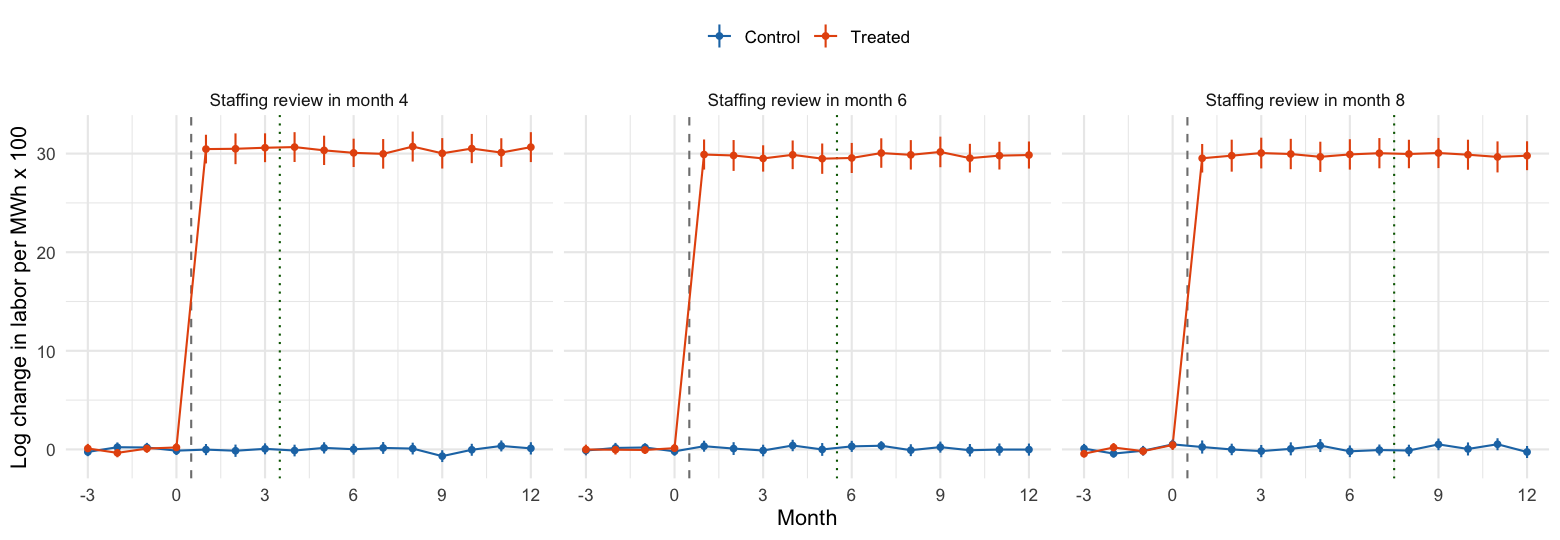

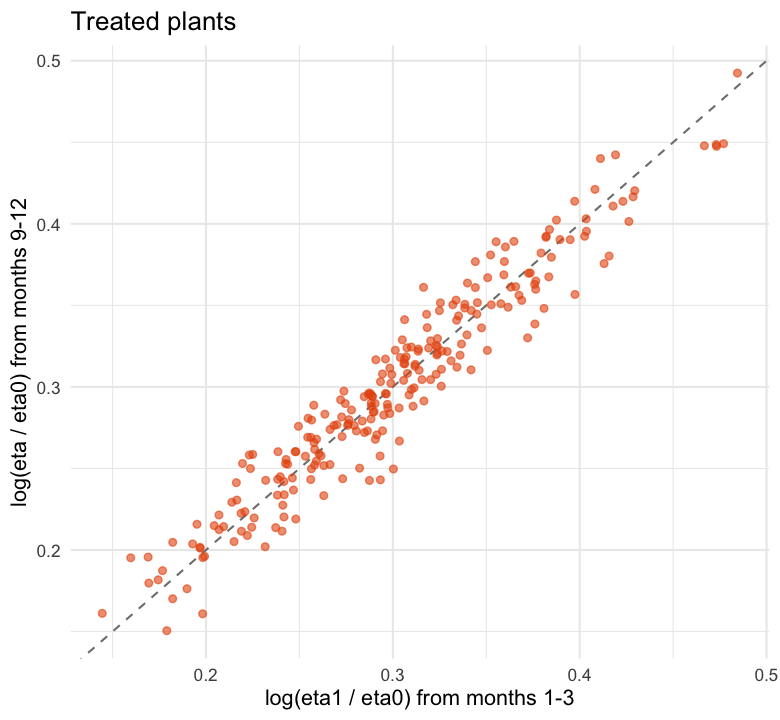

In [ ]:
# 5.4 Does the efficiency change persist? Once labor adjusts, L / E still measures eta if
# plants keep producing without waste. Labor per MWh relative to baseline, by month.
options(repr.plot.width = 13, repr.plot.height = 4.5)
firms |>
  left_join(select(plants, firm_id, eta0), by = "firm_id") |>
  mutate(change = 100 * log((labor / electricity) / eta0),
         cohort = paste("Staffing review in month", adjust_month)) |>
  group_by(cohort, adjust_month, group, month) |>
  summarise(mean = mean(change), se = sd(change) / sqrt(n()), .groups = "drop") |>
  ggplot(aes(month, mean, colour = group)) +
  geom_vline(xintercept = 0.5, linetype = "dashed", colour = "grey50") +
  geom_vline(aes(xintercept = adjust_month - 0.5), linetype = "dotted", colour = "darkgreen") +
  geom_line() +
  geom_pointrange(aes(ymin = mean - 1.96 * se, ymax = mean + 1.96 * se), size = 0.15) +
  facet_wrap(~ cohort) +
  scale_colour_manual(values = group_colours) +
  scale_x_continuous(breaks = seq(-3, 12, 3)) +
  labs(x = "Month", y = "Log change in labor per MWh x 100", colour = NULL)

# Medium-run efficiency (months 9-12) against the short-run estimate, plant by plant
plants <- plants |> mutate(g_m = log((L_m / E_m) / eta0))
plants |>
  group_by(group) |>
  summarise(mean_g_short = mean(g), mean_g_medium = mean(g_m),
            mean_difference = mean(g_m - g), sd_difference = sd(g_m - g),
            correlation = cor(g, g_m)) |>
  mutate(across(where(is.double), \(x) round(x, 4)))
plant_effect(plants, "g_m") |> mutate(across(where(is.double), \(x) round(x, 4)))

options(repr.plot.width = 6.5, repr.plot.height = 6)
plants |>
  filter(treated == 1) |>
  ggplot(aes(g, g_m)) +
  geom_abline(slope = 1, intercept = 0, colour = "grey50", linetype = "dashed") +
  geom_point(alpha = 0.6, colour = "#E6550D") +
  labs(title = "Treated plants", x = "log(eta1 / eta0) from months 1-3",
       y = "log(eta / eta0) from months 9-12")

## 6. Does your explanation predict more than the initial pattern?

> A convincing mechanism should generate additional, testable implications. Derive predictions from your explanation and choose new tables, figures or comparisons to investigate each of the following.
>
> Explain what each piece of evidence establishes. Distinguish predictions tested against additional observations from identities built from the same quantities. Consider at least one alternative explanation, what would distinguish it from yours, and any limits of the available evidence.

### 6(a) The magnitude of later choices

> Does profit maximisation predict plants' later output and input quantities accurately? Use only baseline observations and months 1–3 to recover any required plant parameters. Make predictions before comparing them with the held-out observations in months 9–12. Examine discrepancies as well as fit.

**Parameters, from the baseline and months 1–3 only:**
- productivity $A_i = q/\sqrt{L}$, averaged over the two windows;
- post-consulting efficiency $\eta_{1i} = L_s/E_s$;
- observed prices.

**Prediction.** Once labor is free, the plant chooses $\hat x = \big(pA/(2(w + c/\eta_1))\big)^2$. So $\hat L = \hat x$, $\hat E = \hat x/\eta_1$ and $\hat q = A\sqrt{\hat x}$. We then compare these predictions with months 9–12, which were not used.

In [ ]:
# 6(a).1 Predictions for months 9-12 from the baseline and months 1-3 only.
# Parameters: A from output and labor (baseline and months 1-3), eta1 from months 1-3,
# observed prices. With labor free, the plant chooses x = optimal_x(p, A, w, c, eta1),
# so L = x, E = x / eta1 and q = A sqrt(x). Nothing from months 4-12 is used.
predictions <- plants |>
  mutate(
    x_hat = optimal_x(output_price, A, wage, energy_price, eta1),
    q_hat = A * sqrt(x_hat), L_hat = x_hat, E_hat = x_hat / eta1
  )

# Fit: predicted vs held-out observed medium-run means, as log changes from baseline
fit <- predictions |>
  transmute(firm_id, group, energy_share,
            Output_predicted = log(q_hat / q_b), Output_observed = log(q_m / q_b),
            Labor_predicted = log(L_hat / L_b), Labor_observed = log(L_m / L_b),
            Electricity_predicted = log(E_hat / E_b), Electricity_observed = log(E_m / E_b)) |>
  pivot_longer(-c(firm_id, group, energy_share), names_to = c("variable", ".value"), names_sep = "_") |>
  mutate(variable = factor(variable, levels = c("Output", "Labor", "Electricity")),
         error = observed - predicted)

fit |>
  group_by(variable, group) |>
  summarise(mean_predicted = 100 * mean(predicted), mean_observed = 100 * mean(observed),
            correlation = cor(predicted, observed), rmse = 100 * sqrt(mean(error^2)),
            share_within_5pct = mean(abs(error) < 0.05), .groups = "drop") |>
  mutate(across(where(is.double), \(x) round(x, 3)))

# Aggregate: total predicted vs observed over the 240 treated plants (per month)
predictions |>
  filter(treated == 1) |>
  summarise(across(c(q_hat, q_m, L_hat, L_m, E_hat, E_m), sum)) |>
  pivot_longer(everything()) |>
  mutate(value = round(value))

variable,group,mean_predicted,mean_observed,correlation,rmse,share_within_5pct
<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Output,Control,-0.083,-0.091,0.010,1.950,0.979
Output,Treated,19.620,19.579,0.947,1.924,0.992
Labor,Control,0.000,0.105,0.335,2.458,0.950
Labor,Treated,39.185,39.041,0.981,2.311,0.971
Electricity,Control,-0.024,0.060,0.422,1.750,1.000
Electricity,Treated,9.175,9.043,0.980,1.829,1.000


name,value
<chr>,<dbl>
q_hat,23700
q_m,23703
L_hat,62594
L_m,62492
E_hat,1169272
E_m,1166998


**Fit.** For treated plants the model predicts the following mean log changes from baseline, against what we observe:

| | Predicted | Observed | Correlation across plants |
|---|---|---|---|
| Output | +19.6 | +19.6 | 0.95 |
| Labor | +39.2 | +39.0 | 0.98 |
| Electricity | +9.2 | +9.0 | 0.98 |

The prediction error is about 2 log points (RMSE), the size of the recording noise, and 97–100% of plants are predicted within 5%. Predicted total electricity of the treated plants is within 0.2% of the observed total. For control plants the model correctly predicts no change.

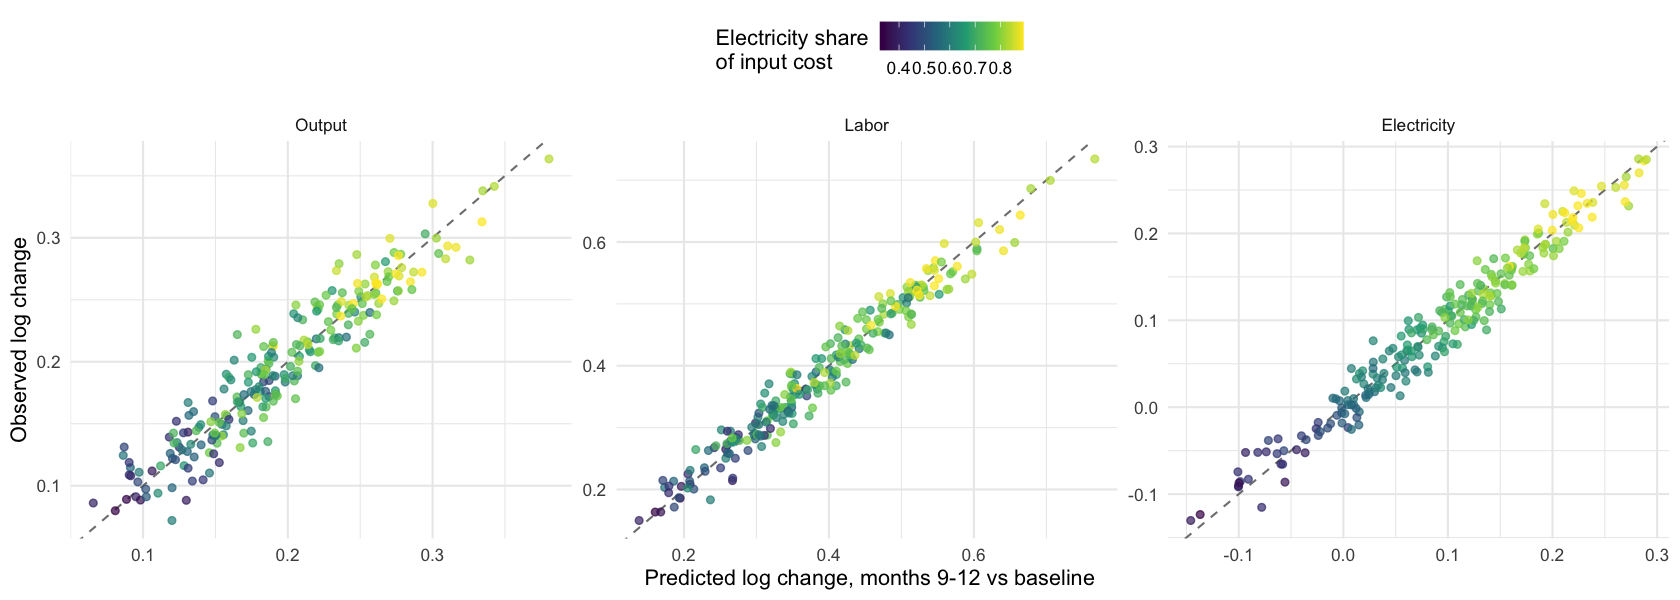

In [ ]:
# 6(a).2 Predicted vs observed medium-run log changes, treated plants (45-degree line)
options(repr.plot.width = 14, repr.plot.height = 5)
fit |>
  filter(group == "Treated") |>
  ggplot(aes(predicted, observed, colour = energy_share)) +
  geom_abline(slope = 1, intercept = 0, colour = "grey50", linetype = "dashed") +
  geom_point(alpha = 0.7) +
  facet_wrap(~ variable, scales = "free") +
  scale_colour_viridis_c() +
  labs(x = "Predicted log change, months 9-12 vs baseline",
       y = "Observed log change", colour = "Electricity share\nof input cost")

**Discrepancies.** For treated plants the prediction errors are unrelated to electricity's cost share, the efficiency gain, sector or cohort (all p > 0.4), so the model does not miss systematically.

For control plants the errors are negatively related to the estimated $g$ (p = 0.02). The reason is recording noise. A control plant whose $\eta_1$ is overestimated by noise is predicted to expand, and then it does not. The same error is present for treated plants, but it is small relative to their true gains.

There is also a small cohort-6 difference for controls (0.8 log points). With this many coefficients, that is probably chance.

**What 6(a) establishes.** This is a genuine out-of-sample test. Profit maximisation with the estimated efficiency gain predicts the size of the medium-run expansion, plant by plant, without using any medium-run data.

In [ ]:
# 6(a).3 Discrepancies. Are the prediction errors (observed - predicted, log points x 100)
# systematic? Regress them on plant characteristics. Errors in eta1 from recording noise
# in months 1-3 enter the predictions directly, so we also compare treated with control.
fit |>
  filter(variable == "Electricity") |>
  left_join(select(plants, firm_id, sector, adjust_month, g), by = "firm_id") |>
  group_by(group) |>
  group_modify(\(d, key) tidy(lm_robust(I(100 * error) ~ energy_share + g + sector + factor(adjust_month), data = d))) |>
  select(group, term, estimate, std.error, p.value) |>
  mutate(across(where(is.double), \(x) round(x, 3)))

group,term,estimate,std.error,p.value
<fct>,<chr>,<dbl>,<dbl>,<dbl>
Control,(Intercept),0.240,0.739,0.745
Control,energy_share,-0.831,0.984,0.399
Control,g,-14.592,6.224,0.020
Control,sectorTextiles,0.037,0.219,0.867
Control,factor(adjust_month)6,0.780,0.279,0.006
Control,factor(adjust_month)8,0.417,0.264,0.115
Treated,(Intercept),0.327,0.917,0.722
Treated,energy_share,-0.472,0.931,0.612
Treated,g,-0.569,1.688,0.736


### 6(b) Production and electricity

> Is the observed change in production large enough to account for the later electricity response, given the efficiency change you estimated? Derive a quantitative criterion and identify which plants meet it. A matching sign alone is not sufficient.

**Criterion.** Without waste, $q = A\sqrt{\eta E}$, so

$$\ln\frac{E_m}{E_b} = 2\ln\frac{q_m}{q_b} - g.$$

Electricity rises above baseline only if output grows by more than half the efficiency gain, $\ln(q_m/q_b) > g/2$. Beyond the sign, the formula gives the electricity change implied by each plant's output growth and its $g$ from months 1–3.

**Result.**
- **Which plants meet it:** 199 of 240 treated plants. Their output grew by more than $g/2$; the average treated plant's output grew by 19.6 log points against $g/2 \approx 15$.
- **Agreement with the sign:** 190 of those 199 plants increased electricity, and 31 of the 41 that do not meet the criterion reduced it, so 92% of plants agree. The 19 mismatches lie close to the line, where noise decides.
- **Size:** the implied electricity change matches the observed one in size (mean 9.2 vs 9.0 log points, correlation 0.94).

**What 6(b) establishes.** The expansion in production is large enough to account for the later increase in electricity, given the efficiency gain. It is close to an **identity** built from the same technology and the same months-9–12 quantities, so it checks consistency with the technology. Unlike 6(a), it does not test profit maximisation.

meets_criterion,electricity_rose,n,share_of_treated
<lgl>,<lgl>,<int>,<dbl>
FALSE,FALSE,31,0.12916667
FALSE,TRUE,10,0.04166667
TRUE,FALSE,9,0.03750000
TRUE,TRUE,190,0.79166667


mean_implied,mean_observed,correlation,rmse
<dbl>,<dbl>,<dbl>,<dbl>
9.15,9.043,0.937,3.285


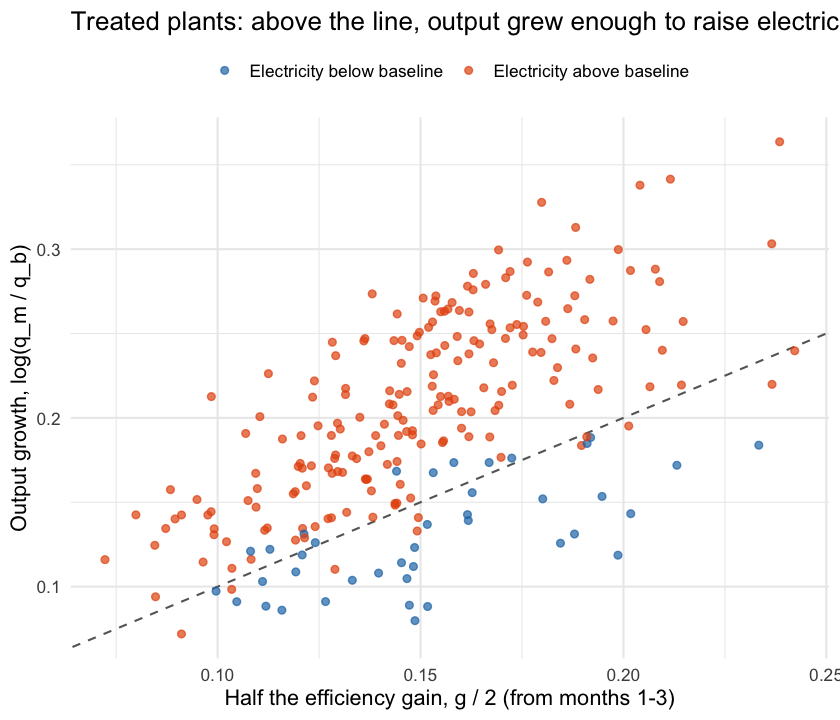

In [ ]:
# 6(b) Production and electricity. Without waste, q = A sqrt(eta E), so
#   log(E_m / E_b) = 2 log(q_m / q_b) - log(eta_m / eta0).
# With the efficiency gain g estimated from months 1-3, electricity rises above its
# baseline only if output grows by more than half the efficiency gain:
#   log(q_m / q_b) > g / 2.
criterion <- plants |>
  filter(treated == 1) |>
  mutate(
    dlog_q = log(q_m / q_b),
    dlog_E = log(E_m / E_b),
    meets_criterion = dlog_q > g / 2,
    implied_dlog_E = 2 * dlog_q - g        # electricity change implied by output and g
  )

# Which plants meet the criterion, and did their electricity actually rise?
criterion |>
  count(meets_criterion, electricity_rose = dlog_E > 0) |>
  mutate(share_of_treated = n / sum(n))

# Implied vs observed electricity change
criterion |>
  summarise(mean_implied = 100 * mean(implied_dlog_E), mean_observed = 100 * mean(dlog_E),
            correlation = cor(implied_dlog_E, dlog_E),
            rmse = 100 * sqrt(mean((dlog_E - implied_dlog_E)^2))) |>
  mutate(across(everything(), \(x) round(x, 3)))

options(repr.plot.width = 7, repr.plot.height = 6)
criterion |>
  ggplot(aes(g / 2, dlog_q, colour = dlog_E > 0)) +
  geom_abline(slope = 1, intercept = 0, colour = "grey40", linetype = "dashed") +
  geom_point(alpha = 0.7) +
  scale_colour_manual(values = c(`FALSE` = "#1F77B4", `TRUE` = "#E6550D"),
                      labels = c("Electricity below baseline", "Electricity above baseline")) +
  labs(title = "Treated plants: above the line, output grew enough to raise electricity",
       x = "Half the efficiency gain, g / 2 (from months 1-3)",
       y = "Output growth, log(q_m / q_b)", colour = NULL)

### 6(c) Differences across firms

> According to your mechanism, which pre-intervention characteristics should predict the strongest later electricity responses? Derive and investigate that prediction. Distinguish differences in the size of the efficiency improvement from differences in firms' responses to a given improvement.

**Prediction.** From Question 4,

$$\Delta\ln E_m = -g - 2\ln(1 - s + s e^{-g}).$$

For a given gain $g$ this increases with $s$, electricity's share of variable cost before consulting, which we observe at baseline as $cE/(wL + cE)$. The reason: where electricity is a large part of costs, an efficiency gain lowers the unit cost of production a lot, so the plant expands a lot.

Electricity rises if $s > 1/(1 + e^{-g/2}) \approx 0.54$ at the mean gain. A larger $g$ raises the response when $s$ is high and lowers it when $s$ is low.

**Two sources of heterogeneity.**
- **Size of the improvement:** $g$, estimated in Question 5. It varies across plants (standard deviation 0.066) but is unrelated to $s$ (correlation 0.015).
- **Response to a given improvement:** governed by $s$, which varies a lot (standard deviation 0.13).

**Result.**
- **Electricity's cost share:** the medium-run electricity change is strongly related to $s$ (correlation 0.95) and only weakly to $g$ (0.13). Holding $g$ fixed, 0.1 more of electricity's cost share raises the response by 6.4 log points. Holding $s$ fixed, a larger gain raises it too, as expected for plants that mostly have $s$ above one half.
- **By quartile:** the observed changes match the model's predictions: −2.5, +6.4, +12.8 and +19.5 log points, against predicted −2.6, +6.6, +12.6 and +19.3. Only in the lowest quartile ($s$ below about 0.59) do some plants (a third) end up above baseline.
- **Sectors:** Chemicals plants respond more because they pay more for electricity, which gives them a higher $s$. Their efficiency gains are no larger.

**What 6(c) establishes.** A pre-intervention characteristic, not used to estimate anything, predicts which plants rebound most, with the magnitude the model implies. Differences across plants come mainly from their response to a given improvement, not from the size of the improvement.

sd_g,sd_s,cor_g_s,cor_dE_s,cor_dE_g,threshold_s_at_mean_g
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.066,0.134,0.015,0.954,0.132,0.537


term,estimate,std.error,p.value
<chr>,<dbl>,<dbl>,<dbl>
(Intercept),-39.067,1.346,0
energy_share,63.560,1.450,0
g,16.073,3.254,0


share_quartile,share_range,mean_g,observed,predicted,share_above_baseline
<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.32-0.59,0.302,-2.462,-2.597,0.333
2,0.60-0.70,0.302,6.404,6.572,1.000
3,0.70-0.79,0.290,12.764,12.565,1.000
4,0.79-0.89,0.307,19.467,19.296,1.000


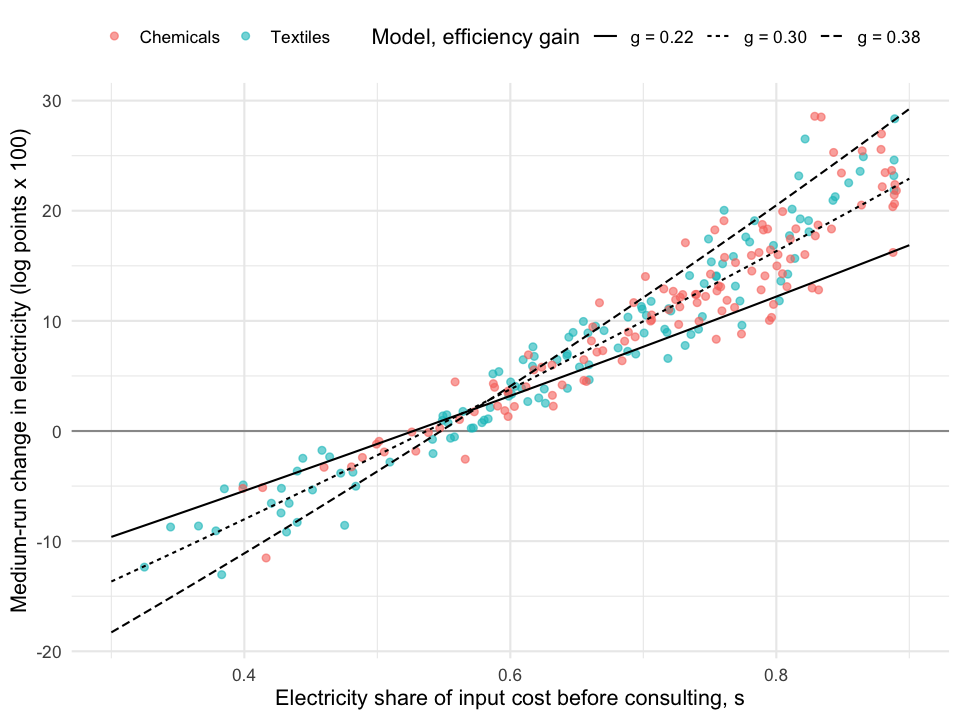

In [ ]:
# 6(c) Differences across firms. The model predicts the medium-run electricity change
#   log(E_m / E_b) = -g - 2 log(1 - s + s exp(-g)),
# where s is electricity's share of input cost before consulting. For a given gain g,
# the response rises with s; electricity rises if s > 1 / (1 + exp(-g / 2)), about 0.54
# for g = 0.30.
heterogeneity <- plants |>
  filter(treated == 1) |>
  mutate(dlog_E = log(E_m / E_b), predicted = dlogE_medium(energy_share, g))

# Two sources of differences: the size of the gain (g) and the response to a given gain (s)
heterogeneity |>
  summarise(sd_g = sd(g), sd_s = sd(energy_share), cor_g_s = cor(g, energy_share),
            cor_dE_s = cor(dlog_E, energy_share), cor_dE_g = cor(dlog_E, g),
            threshold_s_at_mean_g = 1 / (1 + exp(-mean(g) / 2))) |>
  mutate(across(everything(), \(x) round(x, 3)))

lm_robust(I(100 * dlog_E) ~ energy_share + g, data = heterogeneity) |>
  tidy() |> select(term, estimate, std.error, p.value) |>
  mutate(across(where(is.double), \(x) round(x, 3)))

# Mean response by baseline electricity share (quartiles), observed and predicted
heterogeneity |>
  mutate(share_quartile = ntile(energy_share, 4)) |>
  group_by(share_quartile) |>
  summarise(share_range = sprintf("%.2f-%.2f", min(energy_share), max(energy_share)),
            mean_g = mean(g), observed = 100 * mean(dlog_E), predicted = 100 * mean(predicted),
            share_above_baseline = mean(dlog_E > 0)) |>
  mutate(across(where(is.double), \(x) round(x, 3)))

# Response against s, with the model's curve at the 10th, 50th and 90th percentile of g
curves <- expand_grid(energy_share = seq(0.3, 0.9, 0.01),
                      g_level = quantile(heterogeneity$g, c(0.1, 0.5, 0.9))) |>
  mutate(predicted = 100 * dlogE_medium(energy_share, g_level),
         label = sprintf("g = %.2f", g_level))

options(repr.plot.width = 8, repr.plot.height = 6)
ggplot(heterogeneity, aes(energy_share, 100 * dlog_E)) +
  geom_hline(yintercept = 0, colour = "grey60") +
  geom_point(aes(colour = sector), alpha = 0.6) +
  geom_line(data = curves, aes(y = predicted, linetype = label)) +
  labs(x = "Electricity share of input cost before consulting, s",
       y = "Medium-run change in electricity (log points x 100)",
       colour = NULL, linetype = "Model, efficiency gain")

### 6(d) Input relationships and timing

> What relationships between labor and electricity changes should your explanation imply? Do these differ when you compare later observations with baseline rather than with the initial post-intervention period? Investigate these relationships and whether the timing of responses is consistent with the institutional setting.

**Prediction.** Without waste, $\Delta\ln L = \Delta\ln E + \Delta\ln\eta$ between any two periods.
- **Months 9–12 vs baseline:** $\eta$ has risen by $g$, so labor should grow by $g$ more than electricity, plant by plant.
- **Months 9–12 vs months 1–3:** $\eta$ is already at its new level, so labor and electricity should move one for one, with slope 1 and intercept 0.

**Result.**
- **Against the baseline:** labor grows 0.300 log points more than electricity on average, exactly the mean $g$. Plant by plant the gap correlates 0.96 with $g$. Because the gap varies across plants, a regression of electricity changes on labor changes has slope 0.64, not 1.
- **Against months 1–3:** the slope is 0.998 (95% CI 0.977 to 1.019) and the intercept 0.001. Labor and electricity grow one for one.

**Timing (6(d).2).**
- **Before the review month:** labor does not change for any plant, treated or control (no plant moves more than 10%).
- **From the review month:** every treated plant's labor rises, by 39 log points on average.
- **In each cohort,** electricity and output jump in the same month as labor, with no gradual adjustment and no anticipation. Control plants could also adjust labor after their review, but do not, because their efficiency, and hence their optimum, did not change.

The timing follows the staffing rules exactly.

**What 6(d) establishes.** The relationship against months 1–3 is close to an identity given fixed proportions and a constant $\eta$. Its value is in confirming that efficiency did not change after month 1. The timing evidence uses information not used elsewhere, the review month, and tests the claim that the labor constraint caused the delay.

comparison,term,estimate,conf.low,conf.high
<chr>,<chr>,<dbl>,<dbl>,<dbl>
Months 9-12 vs baseline,(Intercept),-0.161,-0.181,-0.140
Months 9-12 vs baseline,dL_vs_baseline,0.643,0.596,0.690
Months 9-12 vs months 1-3,(Intercept),0.001,-0.007,0.009
Months 9-12 vs months 1-3,dL_vs_short,0.998,0.977,1.019


mean_g,gap_vs_baseline,gap_vs_short,cor_gap_vs_baseline_with_g
<dbl>,<dbl>,<dbl>,<dbl>
0.3001,0.3,-1e-04,0.9618


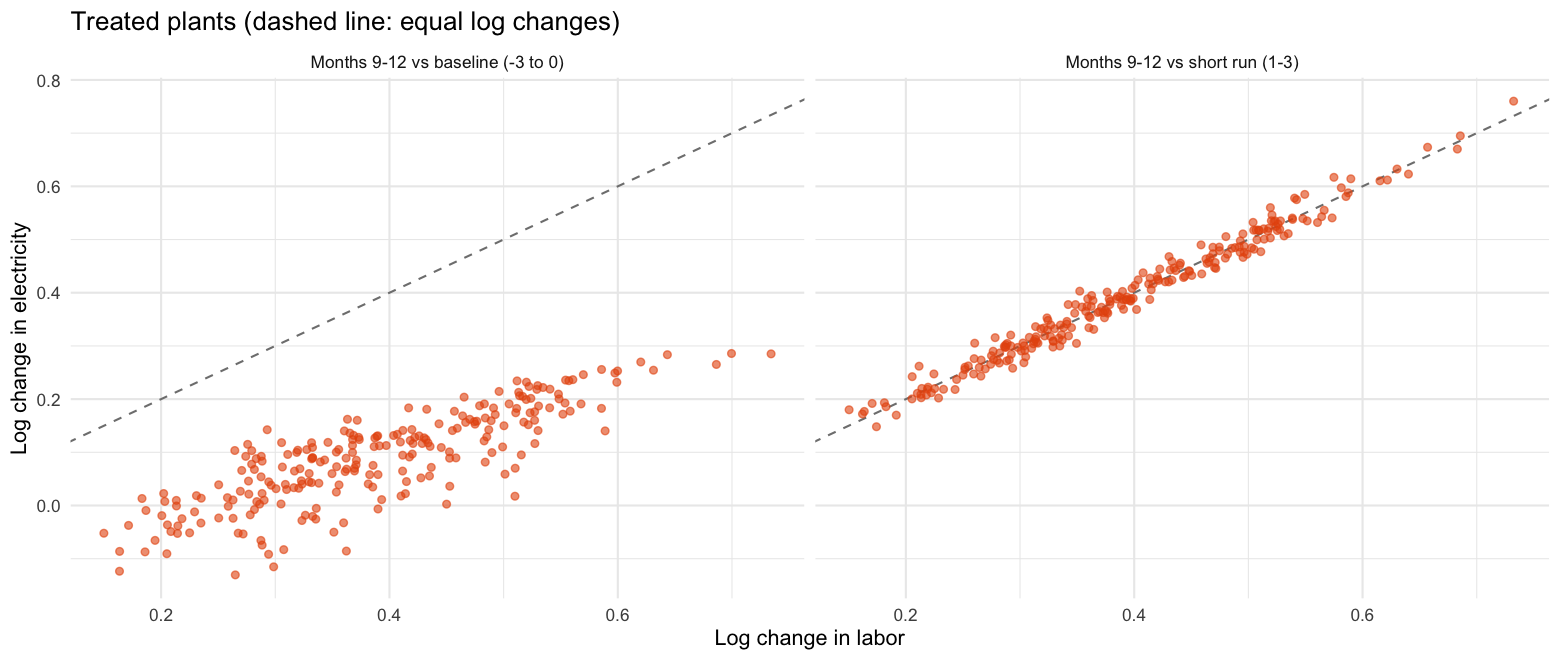

In [ ]:
# 6(d).1 Input relationships. Without waste L = eta E, so for any two periods
#   log change in L = log change in E + log change in eta.
# Against the baseline, eta has risen by g: labor should grow by g more than electricity.
# Against months 1-3, eta is already at its new level: labor and electricity should move
# one for one.
relations <- plants |>
  transmute(firm_id, group, g,
            dL_vs_baseline = log(L_m / L_b), dE_vs_baseline = log(E_m / E_b),
            dL_vs_short = log(L_m / L_s), dE_vs_short = log(E_m / E_s))

bind_rows(
  relations |> group_by(group) |> group_modify(\(d, key) tidy(lm_robust(dE_vs_baseline ~ dL_vs_baseline, data = d))) |>
    mutate(comparison = "Months 9-12 vs baseline"),
  relations |> group_by(group) |> group_modify(\(d, key) tidy(lm_robust(dE_vs_short ~ dL_vs_short, data = d))) |>
    mutate(comparison = "Months 9-12 vs months 1-3")
) |>
  ungroup() |>
  filter(group == "Treated") |>
  select(comparison, term, estimate, conf.low, conf.high) |>
  mutate(across(where(is.double), \(x) round(x, 3)))

# The gap between labor and electricity growth against each comparison period, compared with g
relations |>
  filter(group == "Treated") |>
  summarise(mean_g = mean(g),
            gap_vs_baseline = mean(dL_vs_baseline - dE_vs_baseline),
            gap_vs_short = mean(dL_vs_short - dE_vs_short),
            cor_gap_vs_baseline_with_g = cor(dL_vs_baseline - dE_vs_baseline, g)) |>
  mutate(across(everything(), \(x) round(x, 4)))

options(repr.plot.width = 13, repr.plot.height = 5.5)
relations |>
  filter(group == "Treated") |>
  pivot_longer(-c(firm_id, group, g), names_to = c(".value", "comparison"), names_pattern = "(d[LE])_vs_(.*)") |>
  mutate(comparison = if_else(comparison == "baseline", "Months 9-12 vs baseline (-3 to 0)",
                              "Months 9-12 vs short run (1-3)")) |>
  ggplot(aes(dL, dE)) +
  geom_abline(slope = 1, intercept = 0, colour = "grey50", linetype = "dashed") +
  geom_point(alpha = 0.6, colour = "#E6550D") +
  facet_wrap(~ comparison) +
  labs(title = "Treated plants (dashed line: equal log changes)",
       x = "Log change in labor", y = "Log change in electricity")

group,period,mean_dlog_L,share_moved_over_10pct
<fct>,<chr>,<dbl>,<dbl>
Control,Before review month,0.000,0
Control,From review month,0.001,0
Treated,Before review month,0.000,0
Treated,From review month,0.391,1


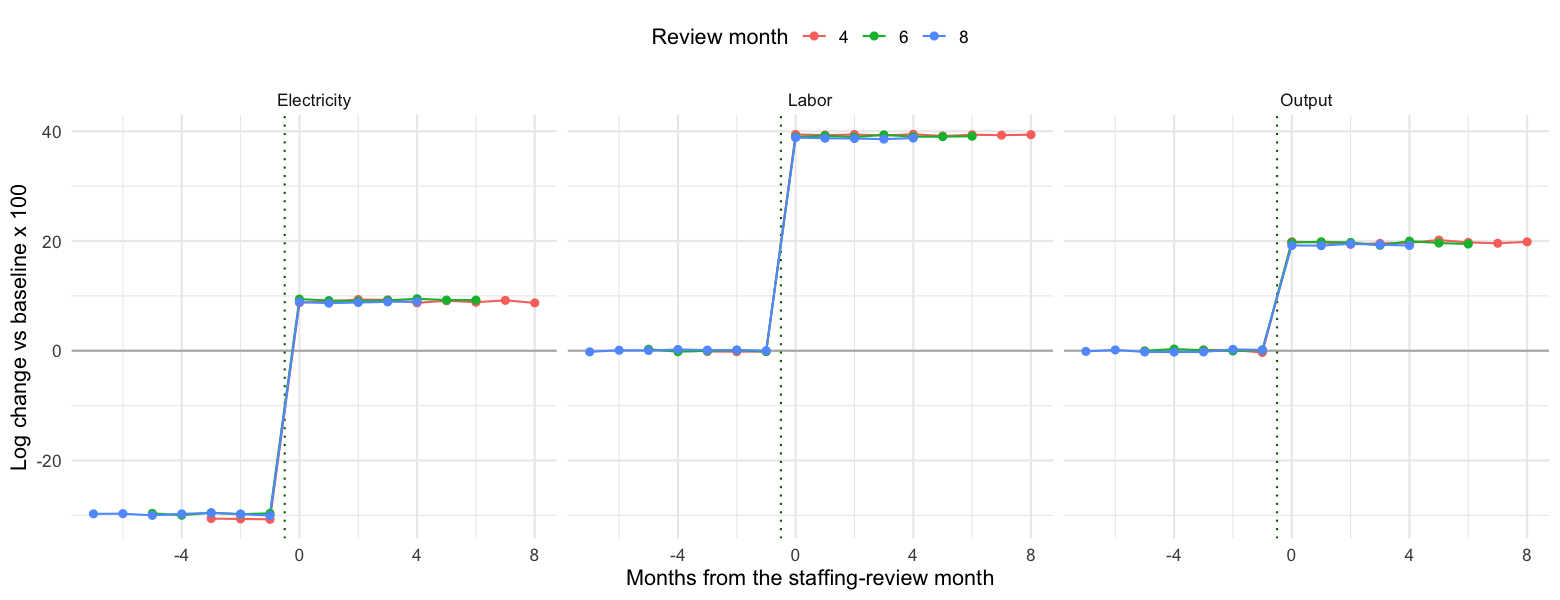

In [ ]:
# 6(d).2 Timing. Months counted from each plant's staffing-review month (0 = review month).
# Mean log change relative to baseline x 100 for treated plants, by cohort.
options(repr.plot.width = 13, repr.plot.height = 5)
firms |>
  filter(treated == 1, month >= 1) |>
  left_join(select(plants, firm_id, L_b, E_b, q_b), by = "firm_id") |>
  mutate(months_from_review = month - adjust_month,
         Electricity = 100 * log(electricity / E_b), Labor = 100 * log(labor / L_b),
         Output = 100 * log(output / q_b)) |>
  pivot_longer(c(Electricity, Labor, Output), names_to = "variable", values_to = "change") |>
  group_by(variable, adjust_month, months_from_review) |>
  summarise(mean = mean(change), .groups = "drop") |>
  ggplot(aes(months_from_review, mean, colour = factor(adjust_month))) +
  geom_hline(yintercept = 0, colour = "grey70") +
  geom_vline(xintercept = -0.5, linetype = "dotted", colour = "darkgreen") +
  geom_line() +
  geom_point() +
  facet_wrap(~ variable) +
  labs(x = "Months from the staffing-review month", y = "Log change vs baseline x 100",
       colour = "Review month")

# Labor changes before the review month, among all plants (should be noise only)
firms |>
  filter(month >= 1) |>
  left_join(select(plants, firm_id, L_b), by = "firm_id") |>
  mutate(period = if_else(month < adjust_month, "Before review month", "From review month"),
         dlog_L = log(labor / L_b)) |>
  group_by(group, period) |>
  summarise(mean_dlog_L = mean(dlog_L), share_moved_over_10pct = mean(abs(dlog_L) > 0.10),
            .groups = "drop") |>
  mutate(across(where(is.double), \(x) round(x, 3)))

### 6. Alternative explanations and limits of the evidence

**Alternative 1: the savings faded.** Plants went back to old habits once the consultants left, so electricity rose back.

This predicts that labor per MWh falls back towards baseline, that output does not rise, and that the reversal happens at a similar time since consulting began, or gradually. The data show the opposite:
- labor per MWh stays 30 log points higher through month 12 (5.4);
- output rises by about 22%;
- the reversal happens in a single month that differs by cohort and coincides exactly with the staffing review (6(d)).

The evidence clearly favours our mechanism.

**Alternative 2: consulting also raised general productivity $A$, or demand, and plants expanded for that reason.**

A higher $A$ would raise output in months 1–3 even with labor fixed, because $q = A\sqrt{L}$ when labor binds. But output did not change in the short run. And the medium-run expansion is predicted accurately from the efficiency gain alone, with $A$ unchanged (6(a)). We cannot rule out an increase in $A$ that starts exactly at the review month, but nothing points to it.

**Limits of the evidence.**
- **Substitution is not identified.** Prices never vary, so we cannot estimate how much plants would substitute between labor and electricity. A technology with a small amount of substitution could fit the same data; fixed proportions are assumed, not proven (see also Question 9).
- **Prices are held constant.** Plants are price-takers. If many plants expanded output by 22%, output prices or wages could change and the rebound could be smaller.
- **Short panel.** The panel ends at month 12, so we do not know whether the medium-run level holds later.
- **Noise.** Recording noise limits plant-level precision, especially for plants near the backfire threshold.
- **Synthetic data.** The data and institutions are synthetic and stylised, so the results do not transfer directly to real plants.

# Part 4: Use the model to advise

## 7. Evaluate a further efficiency improvement

> Suppose a follow-up programme could raise each treated plant's current $\eta$ by a further **20%**, with $A_i$ and prices unchanged. This is additional to the original intervention; there are no observations from the proposed programme.
>
> Predict output, labor, electricity and operating profits with labor first fixed at the current medium-run level, then freely adjustable. Compare both scenarios with the same no-follow-up baseline. Aggregate the results and examine differences across plants. Explain why extrapolating the original percentage effect might be misleading. Profits exclude the unknown cost of delivering consulting.

### Scenarios

**No-follow-up baseline.** Each treated plant's observed medium-run position (months 9–12), with current efficiency $\eta_{now} = L_m/E_m$. The new efficiency is $\eta_{new} = 1.2\,\eta_{now}$, and prices and $A_i$ are unchanged.

- **Labor fixed at $L_m$:** as in the original short run, output is unchanged and $E = L_m/\eta_{new}$, which is 1/1.2 of current electricity.
- **Labor free:** from the first-order condition, effective input scales by $\big((w + c/\eta_{now})/(w + c/\eta_{new})\big)^2$. Labor scales by the same factor, output by its square root, and electricity is the new $x$ divided by $\eta_{new}$. We apply the factor to each plant's observed current level, so recording noise in $A_i$ does not enter the comparison.

Question 6(a) showed that the observed medium run is the model's optimum, so the two ways of setting the baseline agree.

In [ ]:
# 7.1 A further 20% rise in each treated plant's current efficiency.
# Current position (no follow-up): the observed medium run (months 9-12), with current
# efficiency eta_now = L_m / E_m. Prices and A are unchanged.
# - Labor fixed at L_m: the plant needs E = L_m / eta_new, output unchanged.
# - Labor free: the first-order condition scales effective input by
#   x_new / x_now = ((w + c / eta_now) / (w + c / eta_new))^2, applied to the observed
#   current level so that recording noise in A does not enter the comparison.
followup <- plants |>
  filter(treated == 1) |>
  mutate(
    eta_now = L_m / E_m,
    eta_new = 1.2 * eta_now,
    share_now = energy_price * E_m / (wage * L_m + energy_price * E_m),   # current electricity share
    scale = ((wage + energy_price / eta_now) / (wage + energy_price / eta_new))^2
  )

scenarios <- bind_rows(
  followup |> transmute(firm_id, share_now, scenario = "No follow-up",
                        q = q_m, L = L_m, E = E_m, output_price, wage, energy_price),
  followup |> transmute(firm_id, share_now, scenario = "Follow-up, labor fixed",
                        q = q_m, L = L_m, E = L_m / eta_new, output_price, wage, energy_price),
  followup |> transmute(firm_id, share_now, scenario = "Follow-up, labor free",
                        q = q_m * sqrt(scale), L = L_m * scale, E = L_m * scale / eta_new,
                        output_price, wage, energy_price)
) |>
  mutate(scenario = fct_inorder(scenario),
         profit = operating_profit(output_price, wage, energy_price, q, L, E))

# Aggregate over the 240 treated plants, per month, and % change against no follow-up
scenarios |>
  group_by(scenario) |>
  summarise(across(c(q, L, E, profit), sum)) |>
  mutate(across(c(q, L, E, profit), \(x) pct_change(x, first(x)), .names = "{.col}_pct")) |>
  mutate(across(c(q, L, E), round), profit = round(profit / 1e6, 2),
         across(ends_with("_pct"), \(x) round(x, 1))) |>
  rename(`profit (million CU)` = profit)

scenario,q,L,E,profit (million CU),q_pct,L_pct,E_pct,profit_pct
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
No follow-up,23703,62492,1166998,280.33,0.0,0.0,0.0,0.0
"Follow-up, labor fixed",23703,62492,972499,312.41,0.0,0.0,-16.7,11.4
"Follow-up, labor free",26491,78259,1218792,316.88,11.8,25.2,4.4,13.0


### Aggregate results (240 treated plants, per month, against no follow-up)

| | Output | Labor | Electricity | Operating profit |
|---|---|---|---|---|
| Follow-up, labor fixed | 0% | 0% | −16.7% | +11.4% |
| Follow-up, labor free | +11.8% | +25.2% | +4.4% | +13.0% |

With labor fixed, profit rises by about 32 million CU per month, all of it from the electricity bill. With labor free, electricity ends up *above* the no-follow-up level: the 16.7% saving per unit of effective input is more than offset by a 25% expansion. Profits rise in both scenarios, and more when the plant can expand.

threshold,mean_share_now,mean_share_before,share_E_rises_free,E_change_p10,E_change_p90,profit_change_fixed_mean,profit_change_free_mean
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.523,0.619,0.681,0.742,-4.445,10.631,10.295,11.578


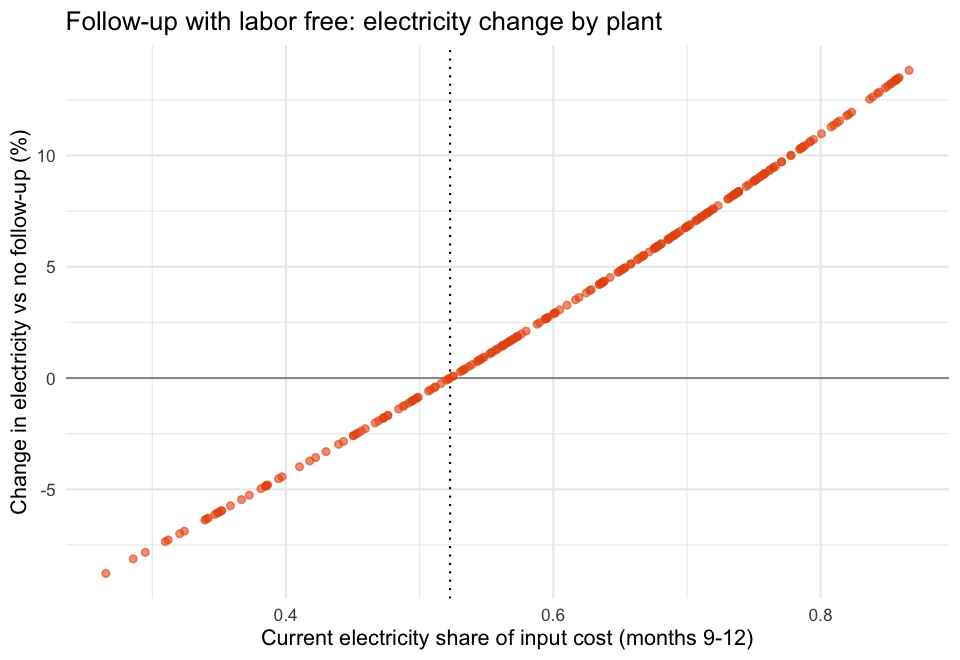

In [ ]:
# 7.2 Differences across plants: % change in electricity against no follow-up, labor free.
# The model predicts electricity rises when the current electricity share of input cost
# exceeds 1 / (1 + sqrt(1 / 1.2)) = 0.52.
by_plant <- scenarios |>
  select(firm_id, share_now, scenario, q, L, E, profit) |>
  pivot_wider(names_from = scenario, values_from = c(q, L, E, profit)) |>
  mutate(E_change_free = pct_change(`E_Follow-up, labor free`, `E_No follow-up`),
         profit_change_free = pct_change(`profit_Follow-up, labor free`, `profit_No follow-up`),
         profit_change_fixed = pct_change(`profit_Follow-up, labor fixed`, `profit_No follow-up`))

by_plant |>
  summarise(threshold = 1 / (1 + sqrt(1 / 1.2)),
            mean_share_now = mean(share_now), mean_share_before = mean(followup$energy_share),
            share_E_rises_free = mean(E_change_free > 0),
            E_change_p10 = unname(quantile(E_change_free, 0.1)), E_change_p90 = unname(quantile(E_change_free, 0.9)),
            profit_change_fixed_mean = mean(profit_change_fixed),
            profit_change_free_mean = mean(profit_change_free)) |>
  mutate(across(everything(), \(x) round(x, 3)))

options(repr.plot.width = 8, repr.plot.height = 5.5)
by_plant |>
  ggplot(aes(share_now, E_change_free)) +
  geom_hline(yintercept = 0, colour = "grey60") +
  geom_vline(xintercept = 1 / (1 + sqrt(1 / 1.2)), linetype = "dotted") +
  geom_point(alpha = 0.6, colour = "#E6550D") +
  labs(title = "Follow-up with labor free: electricity change by plant",
       x = "Current electricity share of input cost (months 9-12)",
       y = "Change in electricity vs no follow-up (%)")

### Differences across plants

With labor free, 74% of treated plants increase electricity, by between −4.4% and +10.6% from the 10th to the 90th percentile. Who increases electricity again depends on electricity's *current* share of cost: it rises when that share exceeds 0.52 for a 20% gain. Profits rise for every plant, by 10.3% on average with labor fixed and by 11.6% with labor free.

### Why extrapolating the original percentage effect is misleading

The original programme raised efficiency by 35% and medium-run electricity by 9.5%. Scaling that in proportion to a 20% gain predicts +5.7%. The model predicts a smaller increase, +3.8% for the average plant, for two reasons:

1. **The response is not proportional to the gain.** It depends on $s$ through a non-linear formula.
2. **The first programme changed the plants.** Electricity is now cheaper in effective terms, so its cost share has fallen from 0.68 to 0.62, closer to the backfire threshold. With the old shares the model would predict +6.2%.

**Horizon.** The original effect also changes sign between the short and the medium run. Which horizon one extrapolates from determines whether the follow-up looks like a 17% saving or a 4% increase.

In [ ]:
# 7.3 Why extrapolating the original percentage effect misleads.
# Naive rule: scale the original medium-run effect on electricity by the size of the
# efficiency gain (in logs). Compare with the model's prediction for the follow-up.
original_g <- mean(followup$g)
original_effect <- mean(log(followup$E_m / followup$E_b))
tibble(
  original_gain_pct = 100 * (exp(original_g) - 1),
  original_effect_on_E_pct = 100 * (exp(original_effect) - 1),
  naive_followup_effect_pct = 100 * (exp(original_effect * log(1.2) / original_g) - 1),
  model_followup_effect_pct = mean(by_plant$E_change_free),
  model_if_shares_had_not_fallen_pct = mean(100 * (exp(dlogE_medium(followup$energy_share, log(1.2))) - 1))
) |>
  mutate(across(everything(), \(x) round(x, 2)))

original_gain_pct,original_effect_on_E_pct,naive_followup_effect_pct,model_followup_effect_pct,model_if_shares_had_not_fallen_pct
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
35,9.46,5.65,3.82,6.24


### Optional policy extension: an electricity levy

> After the original intervention, what plant-specific electricity levy would keep medium-run electricity use at or below its pre-intervention level? Set the levy to zero where none is needed. Let plants reoptimise; report output, profits and tax revenue. Explain why this is not an estimate of an optimal environmental tax or necessarily a feasible uniform policy.

**The levy.** With a levy $t$ per MWh, the unit cost of effective input becomes $w + (c + t)/\eta$. Setting the reoptimised electricity equal to the baseline level $E_b$ gives

$$t = \eta\left[\left(w + \frac{c}{\eta}\right)\sqrt{\frac{E_m}{E_b}} - w\right] - c,$$

and $t = 0$ where medium-run electricity is already at or below baseline.

**Results.**
- **Who pays:** 200 of the 240 treated plants need a levy, on average 19.4 CU per MWh, about 8.6% of their electricity price.
- **Electricity:** total treated electricity falls back to just below its pre-programme level. Plants with a levy end at exactly baseline; the other 40 are already below it.
- **Output and profits:** relative to no levy, output falls by 5.0% and profits by 6.6%.
- **Revenue:** the levy raises about 16.8 million CU per month. Adding the revenue back, the loss is only 0.6%: most of the fall in profits is a transfer to the government.

**Why this is not an optimal environmental tax, nor a feasible uniform policy.**
- **No measure of damage.** An optimal (Pigouvian) tax equals the marginal environmental damage of a MWh. We observe no damages, and "no more than before the programme" is an arbitrary target, not a welfare optimum.
- **Plant-specific rates.** The levy differs by plant, which requires the regulator to know each plant's efficiency, prices and response. Plants could manipulate that information, and different taxes for the same MWh treat firms unequally.
- **Uniform levy.** A single rate high enough for the most responsive plants would over-tax the others, and any lower rate would miss the target for some plants.
- **Partial analysis.** It ignores general-equilibrium effects, untreated plants and other electricity users.

In [ ]:
# 7.4 Optional: plant-specific electricity levy t that keeps medium-run electricity at or
# below the baseline level E_b. With price c + t, the first-order condition scales the
# current effective input by ((w + c/eta) / (w + (c + t)/eta))^2. Setting E = E_b gives
#   t = eta * ((w + c / eta) * sqrt(E_m / E_b) - w) - c,   and t = 0 if E_m <= E_b.
levy <- followup |>
  mutate(
    t = pmax(0, eta_now * ((wage + energy_price / eta_now) * sqrt(E_m / E_b) - wage) - energy_price),
    scale_t = ((wage + energy_price / eta_now) / (wage + (energy_price + t) / eta_now))^2,
    q_t = q_m * sqrt(scale_t), L_t = L_m * scale_t, E_t = L_t / eta_now,
    profit_no_levy = operating_profit(output_price, wage, energy_price, q_m, L_m, E_m),
    profit_levy = operating_profit(output_price, wage, energy_price + t, q_t, L_t, E_t),
    revenue = t * E_t
  )

levy |>
  summarise(plants_with_levy = sum(t > 0),
            mean_levy_CU_per_MWh = mean(t[t > 0]),
            mean_levy_pct_of_price = mean(100 * t[t > 0] / energy_price[t > 0]),
            E_total_baseline = sum(E_b), E_total_no_levy = sum(E_m), E_total_levy = sum(E_t),
            output_change_pct = pct_change(sum(q_t), sum(q_m)),
            profit_change_pct = pct_change(sum(profit_levy), sum(profit_no_levy)),
            tax_revenue_million_CU = sum(revenue) / 1e6,
            profit_change_net_of_revenue_pct = pct_change(sum(profit_levy) + sum(revenue), sum(profit_no_levy))) |>
  pivot_longer(everything()) |>
  mutate(value = round(value, 2))

name,value
<chr>,<dbl>
plants_with_levy,200.00
mean_levy_CU_per_MWh,19.44
mean_levy_pct_of_price,8.64
E_total_baseline,1059289.99
E_total_no_levy,1166998.25
E_total_levy,1051371.95
output_change_pct,-5.03
profit_change_pct,-6.59
tax_revenue_million_CU,16.84


## 8. Brief the policymaker

> Write a 200–300 word briefing assessing the original programme and the proposed follow-up. Explain the mechanism in plain language, ground your recommendation in evidence and uncertainty, and identify the most useful additional information or policy test.
>
> Distinguish electricity savings from output, private profits and social welfare. Environmental damages and programme-delivery costs are not observed. There is no prescribed policy recommendation.

### Policy briefing

**Consulting made plants more efficient, but within a year they used more electricity, not less.**

Half of 480 plants were randomly offered consulting. It raised electricity efficiency by about 35%, and the gain lasted all year. While staffing commitments fixed their workforce, consulted plants produced the same output with 26% less electricity (95% CI 25–27%) than comparable plants without consulting. Once they could hire, in month 4, 6 or 8, they did: by months 9–12 they produced 22% more and used 10% *more* electricity (CI 9–11%), about 107,000 MWh a month across consulted plants.

**Why.** Efficiency makes energy cheaper per unit of production, so expanding becomes profitable. Where electricity is a large share of costs, which is most of these plants, the expansion outweighs the saving per unit. A model built only on the first three months predicted the later output, labor and electricity of each plant closely, and predicted which plants would rebound most.

**Electricity is not welfare.** Plants gained: output and operating profits rose. Whether society gained depends on the environmental damage from the extra electricity and on the cost of consulting, neither of which we observe.

**Follow-up.** A further 20% efficiency gain would cut electricity by 17% only while labor stays fixed. Once plants adjust, our model predicts 12% more output, 13% higher profits and 4% *more* electricity. It is not a tool for cutting electricity on its own.

**Recommendation.** If the goal is lower electricity use, do not expand consulting alone. Pair it with a price signal (an electricity levy of about 9% would keep use at pre-programme levels) or target plants where electricity is a small share of costs.

**Most useful next step.** Estimate the environmental damage per MWh and the cost of consulting, and test the programme with a levy over a longer horizon.

## 9. Optional: a short Cobb–Douglas comparison

> Consider the alternative $q = A_i L^{1/4}(\eta E)^{1/4}$. At unchanged input prices, derive its optimal labor-to-electricity ratio when both inputs can adjust. With labor fixed, determine the direction of the electricity response to improved efficiency. How do these predictions compare with the minimum model and the evidence?
>
> Do not recalibrate or simulate the alternative. Explain why rejecting it would not establish that the minimum technology is uniquely correct.

**Both inputs free.** The first-order conditions are

$$\frac{p\,q}{4L} = w \quad\text{and}\quad \frac{p\,q}{4E} = c,$$

so

$$wL = cE \;\Rightarrow\; \frac{L}{E} = \frac{c}{w}.$$

The labor-to-electricity ratio depends only on relative prices, not on $\eta$. Each input always takes a quarter of revenue.

**Labor fixed at $\bar L$.** The plant chooses $E$ to maximise $pA\bar L^{1/4}\eta^{1/4}E^{1/4} - cE$:

$$\frac{1}{4}pA\bar L^{1/4}\eta^{1/4}E^{-3/4} = c \;\Rightarrow\; E = \left(\frac{pA\bar L^{1/4}\eta^{1/4}}{4c}\right)^{4/3} \propto \eta^{1/3}.$$

Higher efficiency *raises* electricity use, and output, even with labor fixed. Each MWh now delivers more energy services, and with diminishing returns but no fixed proportions it pays to buy more.

**Comparison.**

| | Cobb–Douglas predicts | Minimum model predicts | Observed |
|---|---|---|---|
| Short-run electricity | rises | falls by the gain, output unchanged | −26%, output unchanged |
| $L/E$ | unchanged ($c/w$) | rises by $\eta_1/\eta_0$ | rises by 35% and stays |

The Cobb–Douglas alternative is inconsistent with the evidence on both counts. The minimum model matches it.

**Why rejecting Cobb–Douglas does not prove the minimum technology.** We have rejected one alternative, not all of them. A CES technology with a low but positive elasticity of substitution would behave almost like the minimum model at constant prices. Because prices never vary in these data, we cannot tell how much substitution there is. Other mechanisms, such as adjustment costs, could also generate parts of the pattern. The evidence is consistent with the minimum model, but it does not establish that it is the unique correct technology.